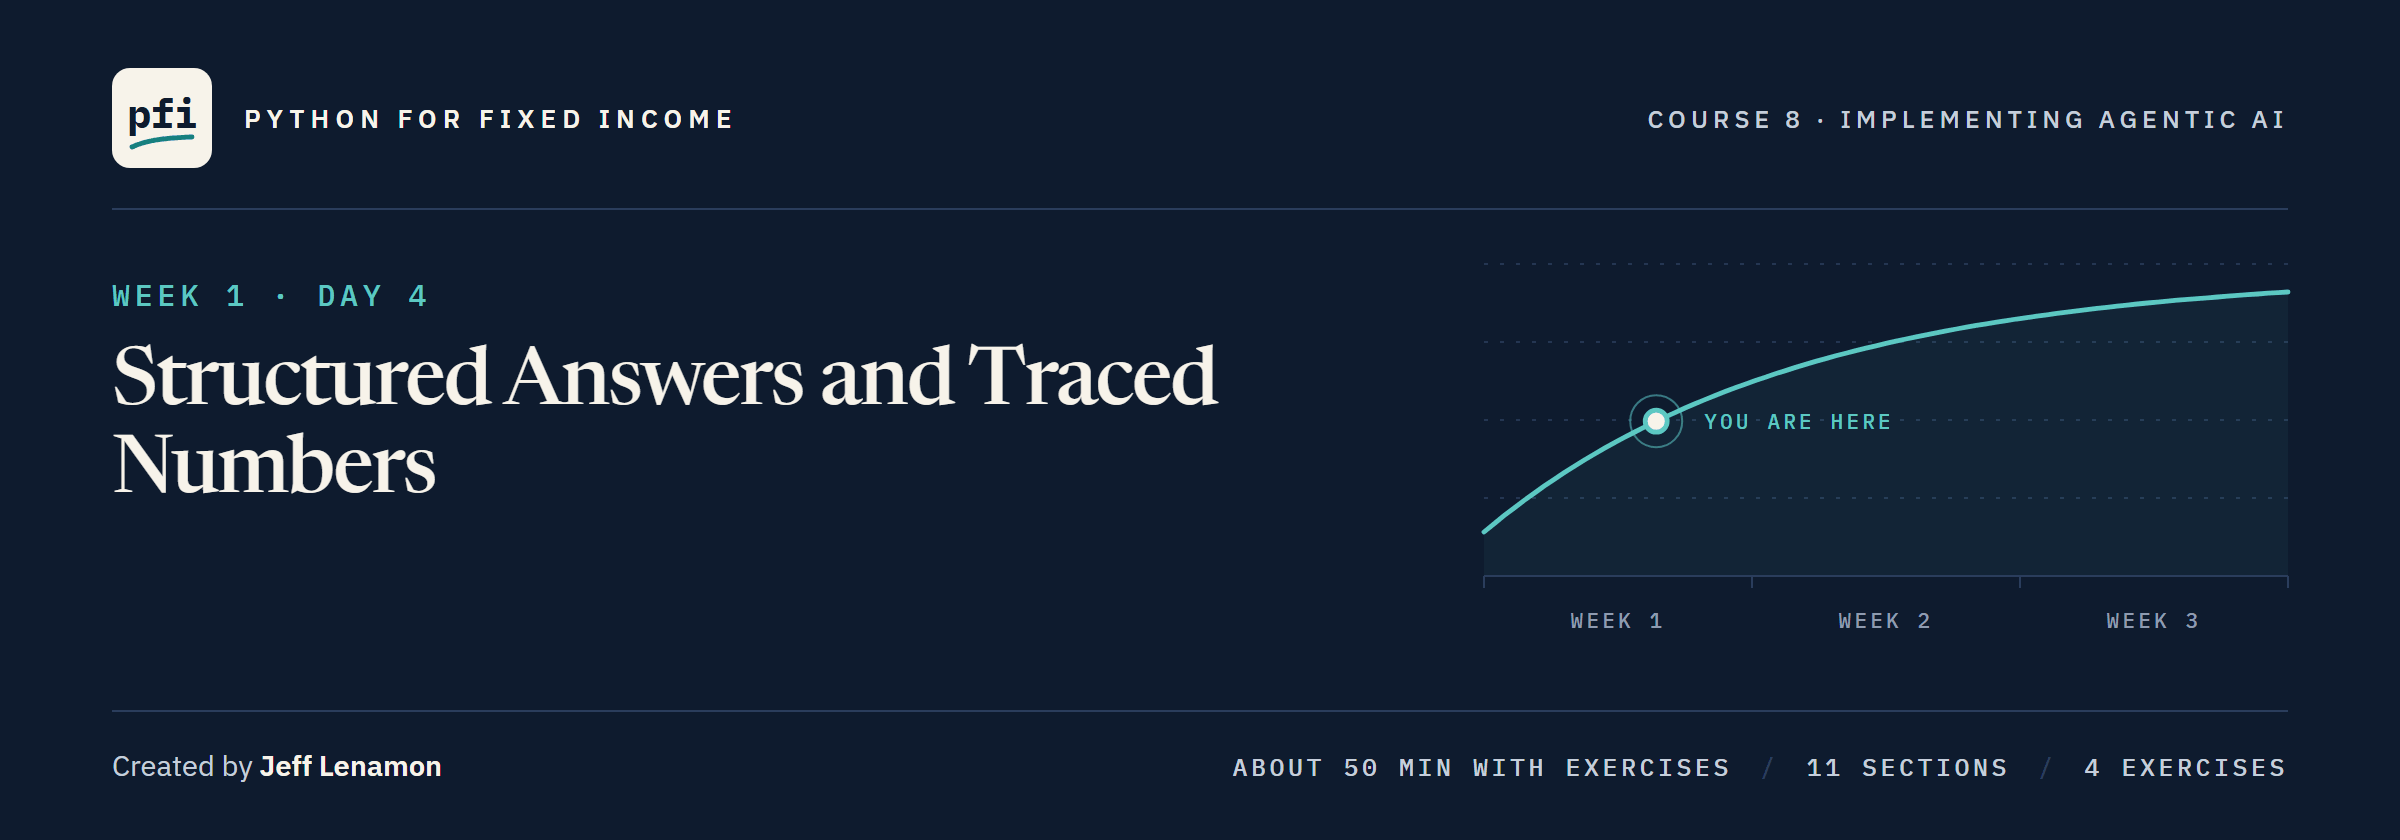

# Structured Answers and Traced Numbers

Week 1, Day 4. Ask for answers whose every number is a figure that cites its tool request, and check each figure with code at its own rounding.

**Data:** `holdings.csv`, 200 bonds as of 2026-09-30: **synthetic**, invented issuers and invented CUSIPs (Course 1), MIT with the code.

**Saved runs:** `course8_agent_runs/`, every request and response of the course's agent runs, recorded once on the author's key and replayed here without one.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day4/04_structured_answers_and_traced_numbers.ipynb)

# Problem Statement

## Business Context

Day 3's six saved answers wrote two tool values whole and rounded four, none wrong in a digit.
Its OAS question came back with 147 bp and a "section 1" that no tool returned.
Free text can only be searched for numbers.
The desk asks for answers whose every number is a field with its unit and the id of the tool request whose result holds it.
It also asks for code that accepts a stated rounding and rejects a wrong digit, a missing request or a wrong unit.
Today's bonds are Day 3's, from the synthetic book: invented issuers and invented CUSIPs.
Every reply was sent once by the course and saved, and the notebook replays it.

## Objectives

Describe an answer as a pydantic model, and ask for it with a strict `response_format`.
Read a structured reply into that model.
Follow each figure to the tool request it cites.
Round a number half away from zero to a written number's decimals.
Write a figure check, and break it on purpose.
Check the numbers of a free-text answer.
Compare figures with answer keys decided before any request.
Measure what a schema adds to a request.

## Data Dictionary

`holdings.csv`, one row a bond of the synthetic book, as of 2026-09-30; the columns read today:

1. `cusip`, `issuer`: the bond's invented identifier and issuer
2. `coupon`: the annual coupon, in percent
3. `maturity`: the maturity date, YYYY-MM-DD
4. `yield_pct`: the yield to maturity, in percent
5. `oas`: the option-adjusted spread, in bp
6. `as_of_date`: the date the book is as of

A `Figure` has a `name`, a `value`, a `unit` (the end of the tool result's key: `per_100`, `years`, `years_bp`) and a `tool_call_id`.
A `DeskAnswer` has a `text`, its `figures` and its `sources`.
A run is Day 2's: its `messages`, `replies` and `stop`.
The figure check's table has one row a figure: `name`, `value`, `unit`, `cited`, `value_matches`, `unit_matches`, `passed`.

## Your Route Through Day 4

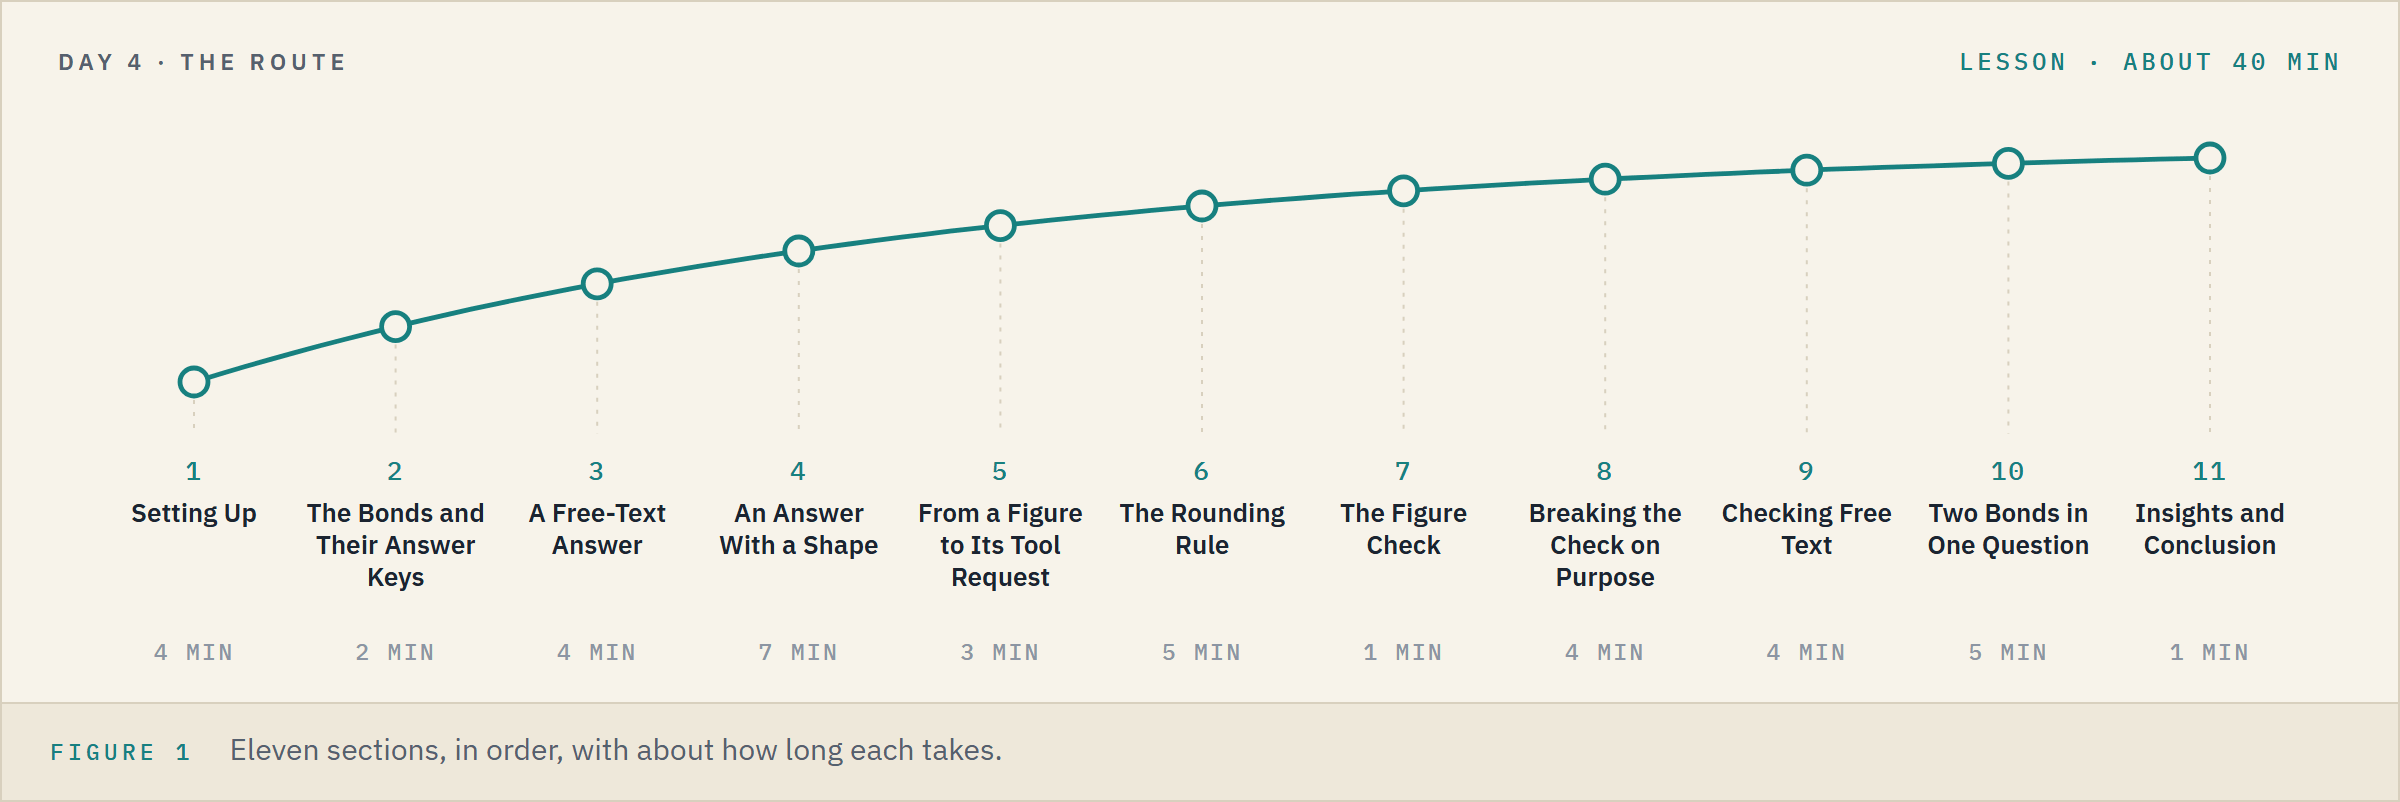

**Time.** About 40 minutes for the lesson, then about 12 for the four exercises.

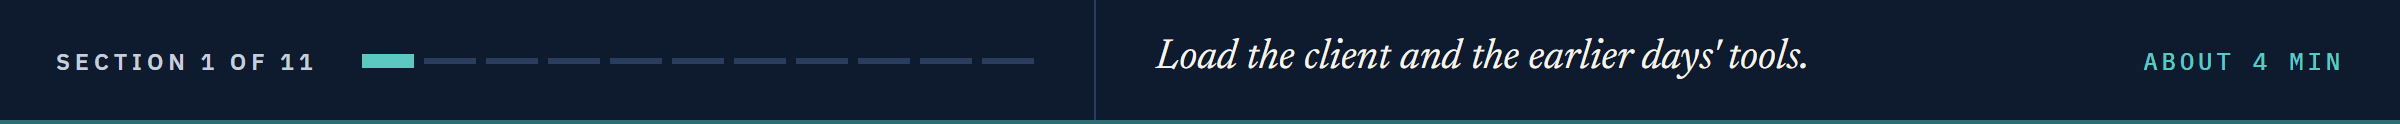

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text as JSON, patterns, wrapping text, dates, and numbers written in decimal (decimal)
import json
import re
import textwrap
from datetime import date
from decimal import ROUND_HALF_UP, Decimal

# to load and work with the data
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## The Model, Live or Replayed

Day 1's client cell, with today's folder of saved runs.

In [3]:
# the model: with your own key each request goes to the model; without one, the course's saved runs answer it
import hashlib
import json
import sys

# Colab does not come with these: this installs them there (on your machine, requirements.txt already did)
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install --quiet openai==3.26.0 python-dotenv==1.2.4")

import httpx2
from dotenv import dotenv_values
from openai import OpenAI

# today's saved runs: one file for each request the course sent, named by the request's fingerprint
RUNS = DATA + "course8_agent_runs/day04/"
MODEL = "gpt-4.1-mini"


def fingerprint(request):
    """The SHA-256 of a request's method, path and JSON body; never its headers, which carry the key."""
    text = json.dumps({"method": request.method, "path": request.url.path, "body": json.loads(request.content)},
                      sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode()).hexdigest()


def replay(request):
    """The saved response to exactly this request."""
    saved = pd.read_json(RUNS + fingerprint(request) + ".json", typ="series")
    return httpx2.Response(200, json=saved["response"])


# your own key, if you have one: an environment variable, my_bondmath\.env (Course 3), or Colab's Secrets panel
key = os.environ.get("OPENAI_API_KEY") or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENAI_API_KEY")
if not key and "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = userdata.get("OPENAI_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None

if key:
    client = OpenAI(api_key=key)
    MODE = "live"
else:
    saved_runs = httpx2.MockTransport(replay)
    client = OpenAI(api_key="replay", http_client=httpx2.Client(transport=saved_runs))
    MODE = "replay"
print(f"Mode: {MODE}.")

Mode: replay.


## The Tools From Earlier Days

The prompt and Day 3's seven schemas are read from Day 3's saved price request; the three cells after it repeat Day 3's tools and Day 2's `run_tools` as written, docstrings cut to one line.

In [4]:
# Day 3's saved exchange for its price question: its request carries Day 1's system prompt and Day 3's seven schemas
day3_saved = pd.read_json(DATA + "course8_agent_runs/day03/c81a77a693bc4f5ebdcb6c4467e442457314ae64f2740573dd772fdc4734a15e.json", typ="series")
DESK_PROMPT = day3_saved["request"]["messages"][0]["content"]
SCHEMAS = day3_saved["request"]["tools"]
print(len(DESK_PROMPT), "characters |", [schema["function"]["name"] for schema in SCHEMAS])

1095 characters | ['price', 'yield_to_maturity', 'accrued_interest', 'modified_duration', 'dv01', 'spread_duration', 'dts']


In [5]:
# Day 3's coupon period and price on any date (Course 2's 30/360), and its modified duration
def coupon_period(settlement, maturity):
    """Days accrued on 30/360 since the last coupon, and the number of coupons left."""
    settle, mature = date.fromisoformat(settlement), date.fromisoformat(maturity)
    coupons_left, previous = 0, mature
    while previous > settle:
        coupons_left = coupons_left + 1
        previous = (pd.Timestamp(mature) - pd.DateOffset(months=6 * coupons_left)).date()
    days = 360 * (settle.year - previous.year) + 30 * (settle.month - previous.month) + settle.day - previous.day
    return days, coupons_left


def dirty_price(settlement, maturity, coupon_pct, yield_pct):
    """The price per 100 of face with accrued interest, semiannual coupons, 30/360."""
    days, coupons_left = coupon_period(settlement, maturity)
    w = (180 - days) / 180
    flows = [coupon_pct / 2] * (coupons_left - 1) + [coupon_pct / 2 + 100]
    return sum(flow / (1 + yield_pct / 200) ** (w + k) for k, flow in enumerate(flows))


def modified_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The modified duration in years: the percent price change for a 100 bp change in yield."""
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    full = dirty_price(settlement, maturity, coupon_pct, yield_pct)
    return {"modified_duration_years": round((down - up) / 0.0002 / full, 6)}

In [6]:
# Day 3's DV01, spread duration and DTS, each checked by pydantic before it runs (Day 3)
import pydantic


def dv01(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The DV01 in price points per 100 of face: the price change for a 1 bp fall in yield."""
    if 0 < coupon_pct < 0.5:
        return {"error": f"coupon_pct {coupon_pct} is below 0.5: write the coupon in percent, 5.0 for a 5% coupon"}
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    return {"dv01_per_100": round((down - up) / 2, 6)}


def spread_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The spread duration in years: the percent price change for a 100 bp move in the spread."""
    return {"spread_duration_years": modified_duration(settlement, maturity, coupon_pct, yield_pct)["modified_duration_years"]}


def dts(spread_duration_years: float, spread_bp: float) -> dict:
    """Duration times spread (DTS) in years times bp: spread duration in years times the spread in bp."""
    # one check Day 3's dts did not have: a 0 means an input was not given, so dts returns an error result
    if spread_duration_years == 0 or spread_bp == 0:
        return {"error": f"dts needs a spread duration and a spread, not {spread_duration_years} years and {spread_bp} bp: a 0 means an input was not given"}
    return {"dts_years_bp": round(spread_duration_years * spread_bp, 6)}


CHECKED = {f.__name__: pydantic.validate_call(f) for f in (modified_duration, dv01, spread_duration, dts)}

In [7]:
# Day 2's run_tools: one tool message for each tool request; a tool that fails goes back to the model as words
def run_tools(assistant_message, tools):
    """Run each tool request of an assistant message and return one tool message for each."""
    tool_messages = []
    for tool_request in assistant_message["tool_calls"]:
        name = tool_request["function"]["name"]
        if name not in tools:
            tool_result = {"error": f"unknown tool {name}; the tools are {list(tools)}"}
        else:
            try:
                tool_result = tools[name](**json.loads(tool_request["function"]["arguments"]))
            except (TypeError, ValueError) as error:
                tool_result = {"error": str(error)}
        tool_messages.append({"role": "tool", "tool_call_id": tool_request["id"],
                              "content": json.dumps({"tool_call_id": tool_request["id"]} | tool_result, sort_keys=True)})
    return tool_messages

The requests offer Day 3's seven schemas, read from Day 3's saved request, so the saved runs replay.

Today's runs execute four tools, and a live reply that names any other gets `run_tools`' unknown-tool error result.

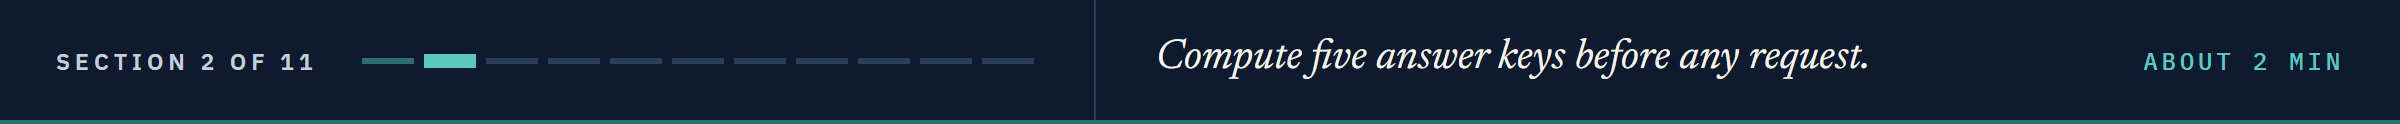

# The Bonds and Their Answer Keys

## Four Bonds of the Book

In [8]:
# the desk's book: 200 bonds, synthetic (invented issuers and CUSIPs), as of 2026-09-30; the four today's questions ask about
holdings = pd.read_csv(DATA + "holdings.csv")
CUSIPS = ["99126WAE0", "99080CAE8", "99039NAC0", "99033HAF2"]
four = holdings.set_index("cusip").loc[CUSIPS]
four[["issuer", "coupon", "maturity", "yield_pct", "oas", "as_of_date"]]

,issuer,coupon,maturity,yield_pct,oas,as_of_date
cusip,,,,,,
99126WAE0,Bezimer Power,4.125,2029-07-16,4.516,62,2026-09-30
99080CAE8,Bezane Finance,7.000,2032-06-18,5.606,147,2026-09-30
99039NAC0,Bezoquil Freight,5.125,2030-06-03,5.509,153,2026-09-30
99033HAF2,Clavane Foods,7.000,2050-02-26,6.393,183,2026-09-30


## The Questions

In [9]:
# the desk's four questions, worded as the course recorded them
QUESTIONS = {
    "duration": "As of 2026-09-30, what is the modified duration in years, the percent price change for a 100 bp change in yield, of bond 99126WAE0 of the synthetic holdings, a 4.125% bullet settling 2026-09-30 and maturing 2029-07-16 at a 4.516% yield?",
    "dts": "As of 2026-09-30, what is the DTS, the spread duration in years times the spread in bp, of bond 99080CAE8 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp?",
    "oas": "As of 2026-09-30, what is the option-adjusted spread in bp of bond 99080CAE8 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield?",
    "two": "As of 2026-09-30, what is the DV01 per 100 of face, the price change for a 1 bp fall in yield, of bond 99039NAC0 of the synthetic holdings, a 5.125% bullet settling 2026-09-30 and maturing 2030-06-03 at a 5.509% yield, and of bond 99033HAF2 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield?"}

## The Answer Keys, Before Any Request

`terms(cusip)` reads a bond's terms from the file, and `*terms(...)` hands them over as separate arguments (Course 2).

In [10]:
# every measure the questions ask for, from the tools themselves on the file's terms
SETTLE = "2026-09-30"


def terms(cusip):
    """A bond's settlement, maturity, coupon and yield, as the tools take them."""
    return SETTLE, four.loc[cusip, "maturity"], float(four.loc[cusip, "coupon"]), float(four.loc[cusip, "yield_pct"])


spread_years = spread_duration(*terms("99080CAE8"))["spread_duration_years"]
KEYS = {"duration 99126WAE0": modified_duration(*terms("99126WAE0"))["modified_duration_years"],
        "spread duration 99080CAE8": spread_years,
        "DTS 99080CAE8 at 147 bp": dts(spread_years, float(four.loc["99080CAE8", "oas"]))["dts_years_bp"],
        "DV01 99039NAC0": dv01(*terms("99039NAC0"))["dv01_per_100"], "DV01 99033HAF2": dv01(*terms("99033HAF2"))["dv01_per_100"]}
print(KEYS)

{'duration 99126WAE0': 2.587515, 'spread duration 99080CAE8': 4.626971, 'DTS 99080CAE8 at 147 bp': 680.164737, 'DV01 99039NAC0': 0.032627, 'DV01 99033HAF2': 0.127083}


Five keys from four bonds, each to the tool's 6 decimals.

**Every number today's answers state can be checked against these keys.**

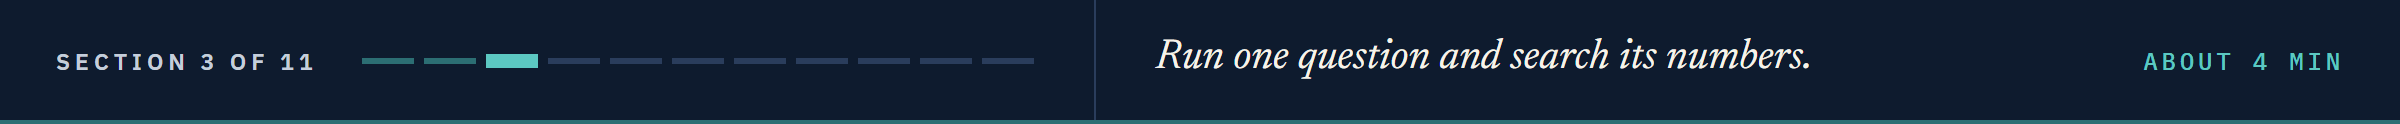

# A Free-Text Answer

## Day 2's Loop, One Argument More

Today's `agent_loop` is Day 2's with one argument more: a `response_format`, added to the body when one is given.

In [11]:
# Day 2's loop: send, act, stop, with a step limit; a response_format joins the body only when given
def agent_loop(client, question, tools, schemas, response_format=None, max_steps=8):
    """Run a question until a reply holds text or max_steps requests are sent, and return the run."""
    messages = [{"role": "system", "content": DESK_PROMPT}, {"role": "user", "content": question}]
    # today's saved runs were sent with max_tokens 400
    body = {"model": MODEL, "tools": schemas, "temperature": 0, "seed": SEED, "max_tokens": 400,
            "parallel_tool_calls": False}
    if response_format:
        body = body | {"response_format": response_format}
    replies = []
    for step in range(max_steps):
        request_body = body | {"messages": messages}
        reply = client.chat.completions.create(**request_body)
        replies.append(reply)
        message = reply.choices[0].message
        if not message.tool_calls:
            answer = {"role": "assistant", "content": message.content}
            return {"messages": messages + [answer], "replies": replies, "stop": "answer"}
        sent = {"role": "assistant", "content": None, "tool_calls": [t.model_dump(exclude_none=True) for t in message.tool_calls]}
        messages = messages + [sent] + run_tools(sent, tools)
    return {"messages": messages, "replies": replies, "stop": "max_steps"}

Without the argument, the body is Day 2's but for its `max_tokens`.

## The Duration Question as Free Text

In [12]:
# the duration question, as Day 3 asked it: free text, the four checked tools
run_free = agent_loop(client, QUESTIONS["duration"], CHECKED, SCHEMAS)
print(run_free["stop"], "| prompt tokens per request:", [reply.usage.prompt_tokens for reply in run_free["replies"]])

answer | prompt tokens per request: [1074, 1164]


In [13]:
# agent answer
free_answer = run_free["messages"][-1]["content"]
print(free_answer)

As of 2026-09-30, the modified duration in years, the percent price change for a 100 bp change in yield, of bond 99126WAE0, a 4.125% bullet settling 2026-09-30 and maturing 2029-07-16 at a 4.516% yield, is approximately 2.588 years.


One tool request, then the text, which reads word for word as Day 3's saved duration answer.

## What the Run Holds

In [14]:
# each tool request's id in the run, with the result its tool message carried
def tool_results(run):
    """Each tool request id of a run, with the result its tool message carried."""
    return {m["tool_call_id"]: json.loads(m["content"]) for m in run["messages"] if m["role"] == "tool"}


print(tool_results(run_free))

{'call_cF6AHi2x6ofIhC0kpNaoIFa5': {'modified_duration_years': 2.587515, 'tool_call_id': 'call_cF6AHi2x6ofIhC0kpNaoIFa5'}}


## Day 1's Number Check Again

In [15]:
# Day 1's number check: every number in the answer, those the question wrote, and those a tool result holds as written
NUMBER = r"\b\d+(?:\.\d+)?"
asked = re.findall(NUMBER, QUESTIONS["duration"])
numbers = re.findall(NUMBER, free_answer)
results_as_text = [str(value) for result in tool_results(run_free).values() for value in result.values()]
print(len(numbers), "numbers |", len([n for n in numbers if n in asked]), "written in the question | the rest:",
      [n for n in numbers if n not in asked], "| as written in a result:", [n for n in numbers if n in results_as_text])

14 numbers | 13 written in the question | the rest: ['2.588'] | as written in a result: []


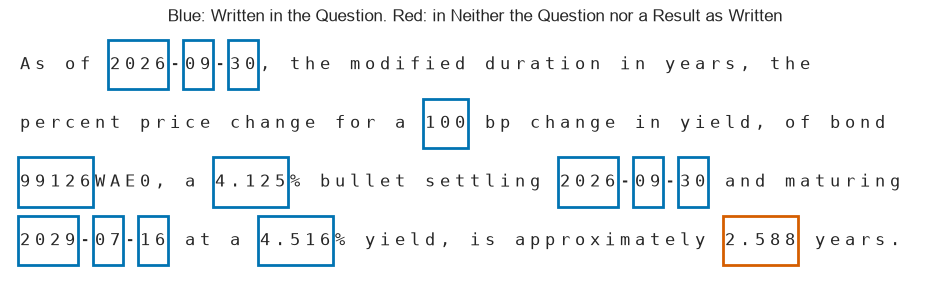

In [16]:
# Day 1's highlighted answer as a function: each number boxed, blue if the question wrote it, red if not
def boxed(answer, asked, title):
    """Draw an answer one character to a cell, each number boxed in its source's colour."""
    lines = textwrap.wrap(answer, 60, break_on_hyphens=False)
    fig, ax = plt.subplots(figsize=(12, 0.6 * len(lines) + 0.8))
    for row, line in enumerate(lines):
        for column, character in enumerate(line):
            ax.text(column, -row, character, ha="center", va="center", family="monospace", fontsize=12)
        for found in re.finditer(NUMBER, line):
            colour = sns.color_palette()[0] if found.group() in asked else sns.color_palette()[3]
            ax.add_patch(plt.Rectangle((found.start() - 0.5, -row - 0.42), len(found.group()), 0.84, fill=False, edgecolor=colour, lw=2))
    ax.set_xlim(-1, 61)
    ax.set_ylim(-len(lines) + 0.4, 0.6)
    ax.set_axis_off()
    ax.set_title(title)
    plt.show()


boxed(free_answer, asked, "Blue: Written in the Question. Red: in Neither the Question nor a Result as Written")

Thirteen numbers repeat the question.

2.588 is in no result as written: the tool returned 2.587515, and the text rounds it.

The text never says which tool request 2.588 came from.

**Day 1's two gaps are open: a schema gives each number its request, and a rounding rule gives it its decimals.**

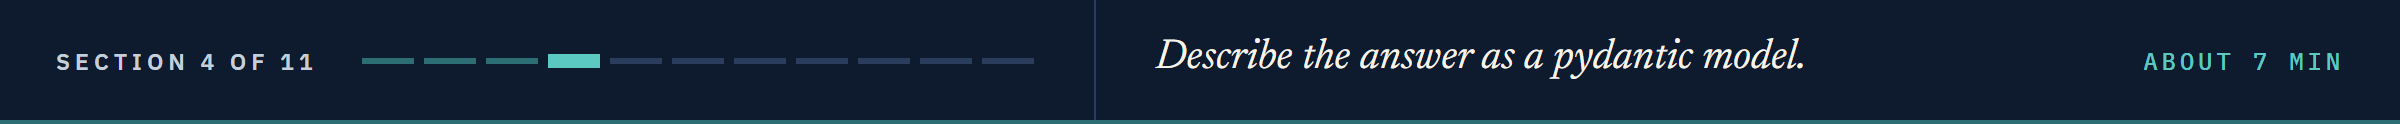

# An Answer With a Shape

## Figure and DeskAnswer

Course 7's Day 12 described an extraction as a pydantic model; today the answer itself is one.
`pydantic.Field(description=...)` gives a field its description, and `model_config = pydantic.ConfigDict(extra="forbid")` writes `"additionalProperties": false` into the schema, as Day 1's tool schemas carry it.
`list[Figure]` types a field as a list of `Figure`s.

In [17]:
# one number of an answer, with the id of the tool request whose result holds it (descriptions as the course recorded them)
class Figure(pydantic.BaseModel):
    """One number in an answer, with the tool request whose result it came from."""
    model_config = pydantic.ConfigDict(extra="forbid")
    name: str = pydantic.Field(description="what the number is, for example 'DV01 of the 2031 bond'")
    value: float = pydantic.Field(description="the number, written to the decimals stated in the text")
    unit: str = pydantic.Field(description="the unit as the tool result's key ends: per_100, pct, bp, usd, years")
    tool_call_id: str = pydantic.Field(description="the id of the tool request whose result holds the number")

In [18]:
# the answer: its text, every number in it as a Figure, and what it used
class DeskAnswer(pydantic.BaseModel):
    """An agent's answer: the text, every number in it as a Figure, and the documents or files it used."""
    model_config = pydantic.ConfigDict(extra="forbid")
    text: str = pydantic.Field(description="the answer in plain sentences")
    figures: list[Figure] = pydantic.Field(description="every number the text states")
    sources: list[str] = pydantic.Field(description="the files, sections, or statement dates used")

The descriptions travel with the schema, so they are prompt, as a tool's docstring is.

`DESK_PROMPT`'s last sentence already asks for a `call_` id in each figure.

## The Response Format

`response_format` asks for a final reply that fits a JSON schema; `"strict": True` asks for an exact fit.

In [19]:
# the schema pydantic writes for DeskAnswer, as a response_format
ANSWER_FORMAT = {"type": "json_schema",
                 "json_schema": {"name": "DeskAnswer", "schema": DeskAnswer.model_json_schema(), "strict": True}}
print(len(json.dumps(ANSWER_FORMAT)), "characters |", list(ANSWER_FORMAT["json_schema"]["schema"]["properties"]))

1467 characters | ['text', 'figures', 'sources']


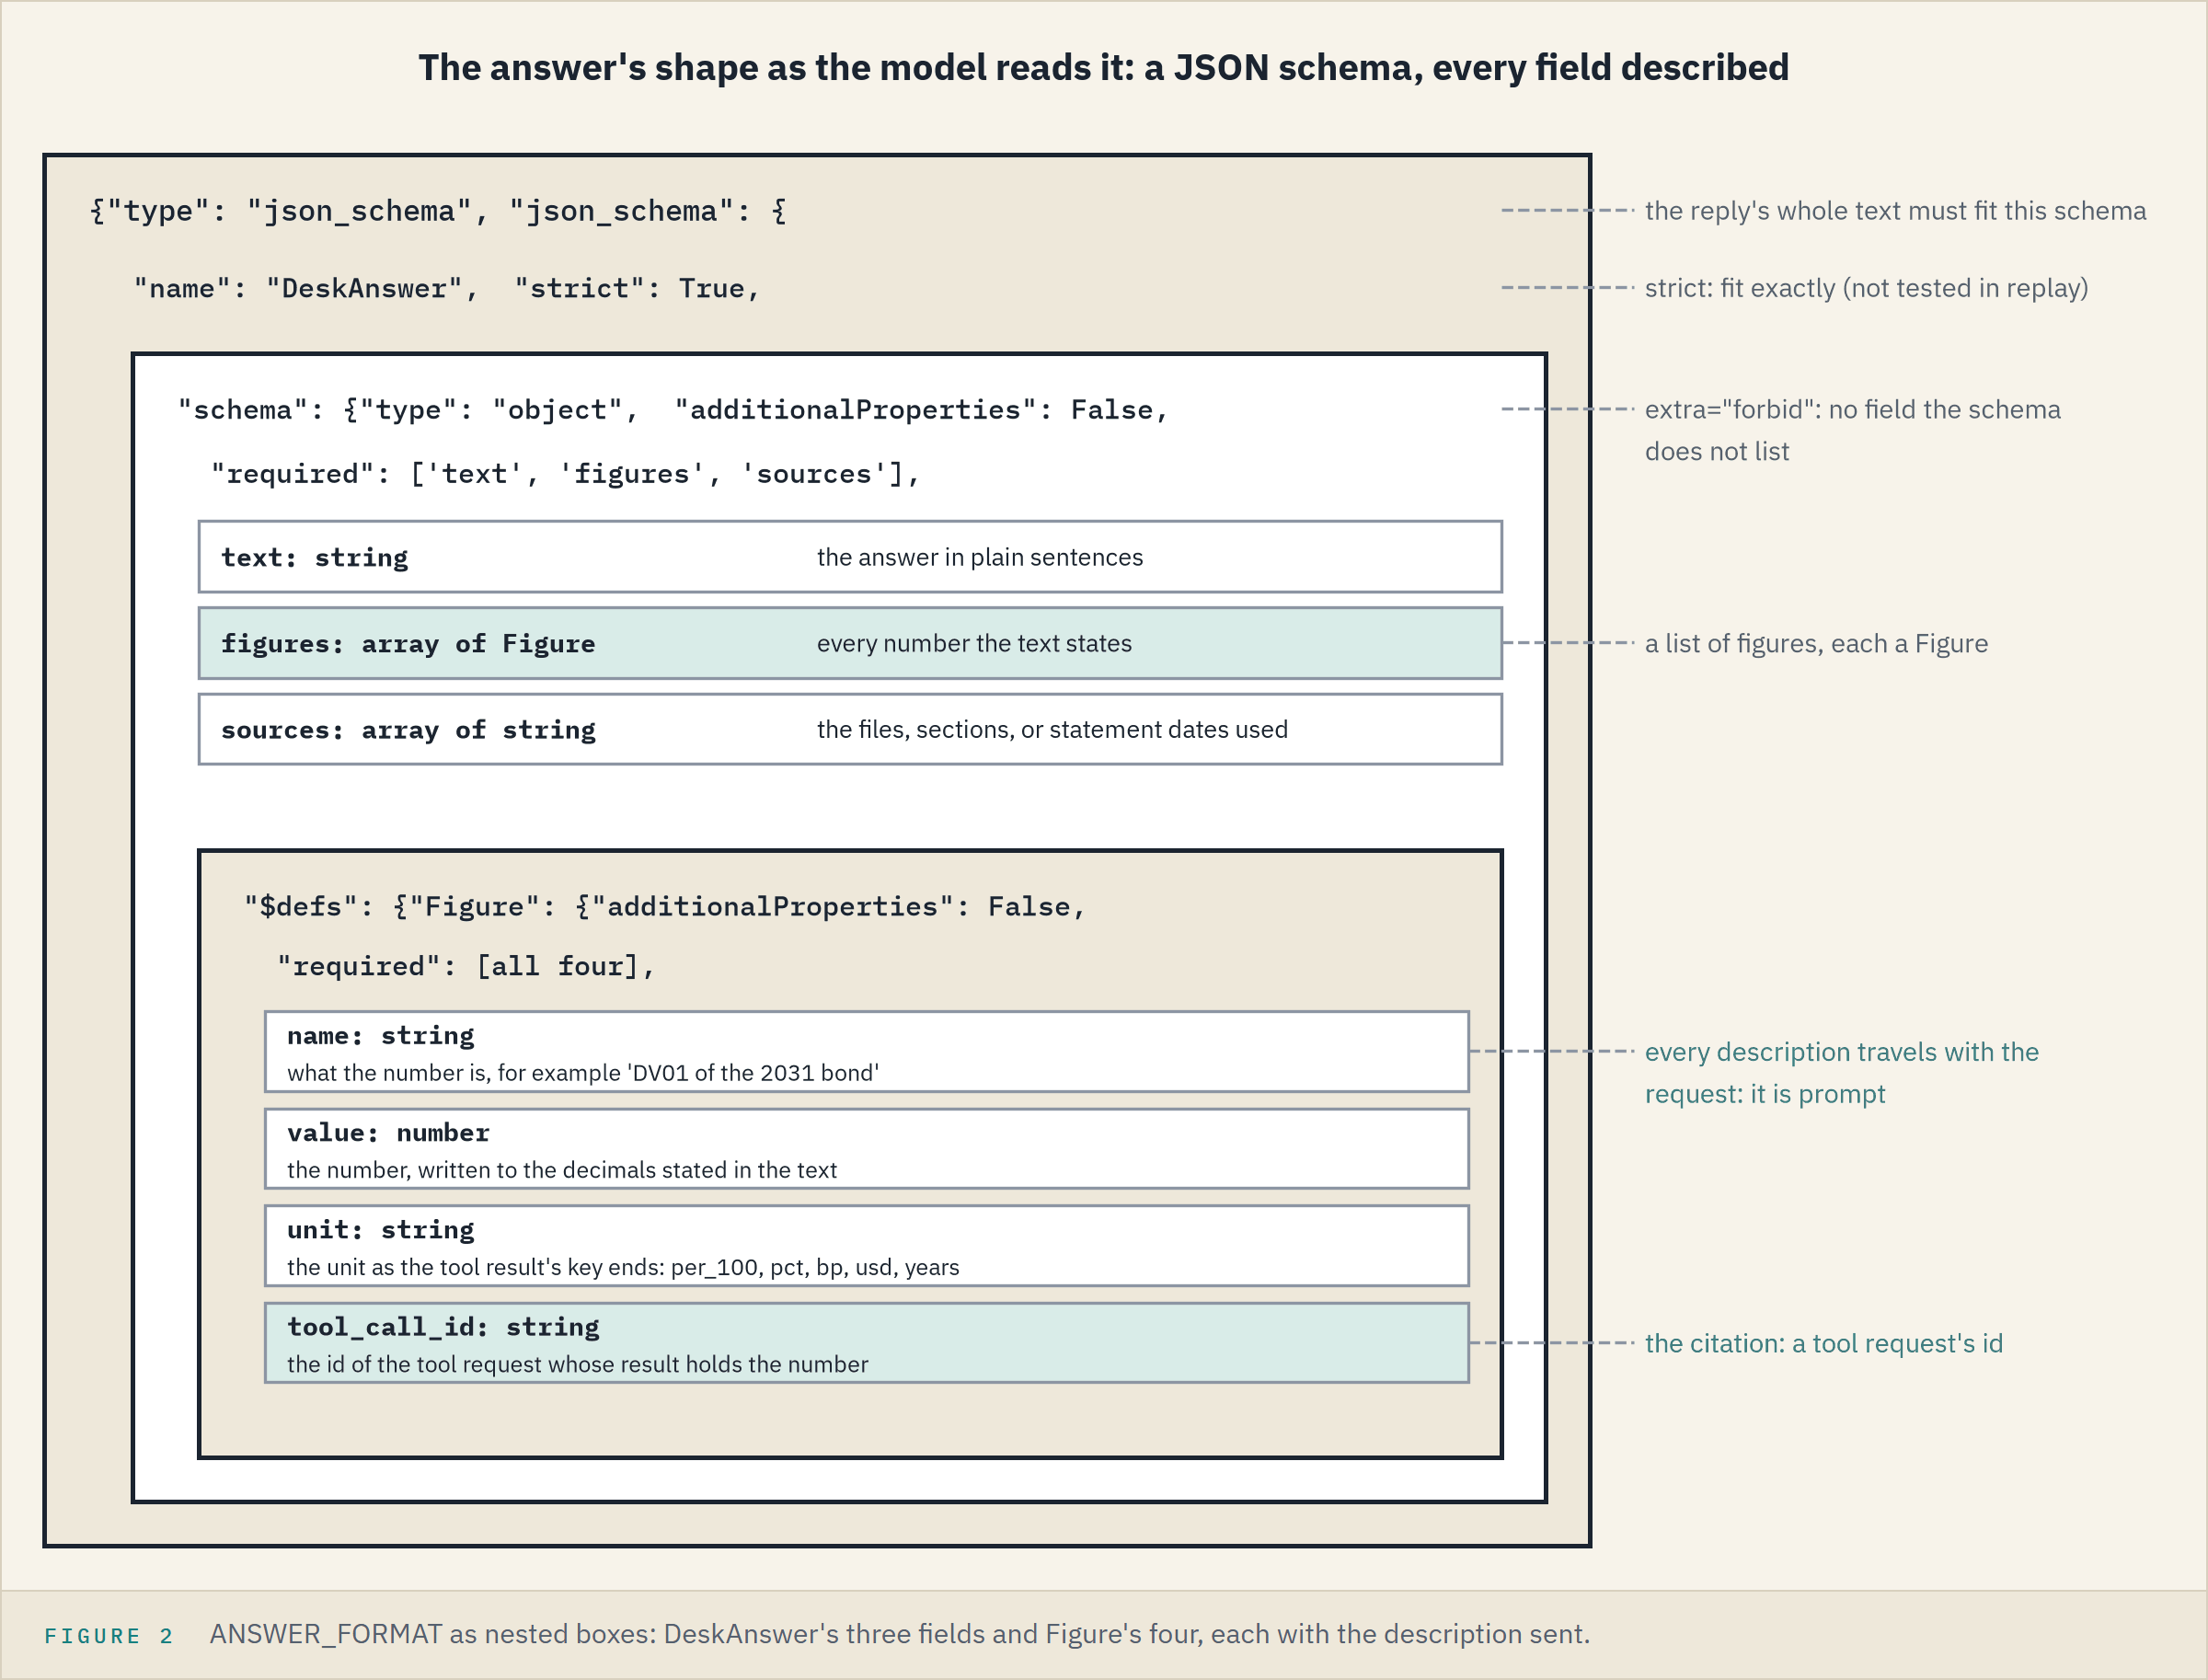

Replay sends nothing, so what the provider does with a reply that would not fit is not tested here.

**Predict 1**

The free-text run's first request carried 1,074 prompt tokens.
`ANSWER_FORMAT` is 1,467 characters of JSON.
Q. With `ANSWER_FORMAT` added, how many prompt tokens does the same first request carry? Write down a number.

## The Duration Question, Structured

In [20]:
# the same question with ANSWER_FORMAT
run_duration = agent_loop(client, QUESTIONS["duration"], CHECKED, SCHEMAS, response_format=ANSWER_FORMAT)
print(run_duration["stop"], "| prompt tokens per request:", [reply.usage.prompt_tokens for reply in run_duration["replies"]])

answer | prompt tokens per request: [1356, 1446]


In [21]:
# agent answer
print(run_duration["messages"][-1]["content"])

{"text":"As of 2026-09-30, the modified duration of bond 99126WAE0, a 4.125% bullet maturing on 2029-07-16 and yielding 4.516%, is approximately 2.588 years. This means the bond's price would change by about 2.588% for a 100 basis point change in yield.","figures":[{"name":"Modified duration of bond 99126WAE0","value":2.587515,"unit":"years","tool_call_id":"call_ReR4zEhA1ezTVw3Wji8NBh5a"}],"sources":["2026-09-30"]}


The answer is one JSON text with three fields, `text`, `figures` and `sources`, and nothing else.

## Reading the Reply as a DeskAnswer

`DeskAnswer.model_validate_json(text)` reads JSON text into the model, and raises a `ValidationError` if it does not fit.

In [22]:
# the reply as a DeskAnswer: its text, each figure's four fields, and its sources
answer_duration = DeskAnswer.model_validate_json(run_duration["messages"][-1]["content"])
for figure in answer_duration.figures:
    print(figure.name, "|", figure.value, figure.unit, "|", figure.tool_call_id)
print("sources:", answer_duration.sources, "| the run's tool requests:", list(tool_results(run_duration)))

Modified duration of bond 99126WAE0 | 2.587515 years | call_ReR4zEhA1ezTVw3Wji8NBh5a
sources: ['2026-09-30'] | the run's tool requests: ['call_ReR4zEhA1ezTVw3Wji8NBh5a']


The figure names the run's one tool request, and its value is the tool's 2.587515, whole.

The text still says approximately 2.588.

`sources` holds the book's as-of date.

**A number now arrives with its unit and the request that returned it.**

## What the Schema Costs

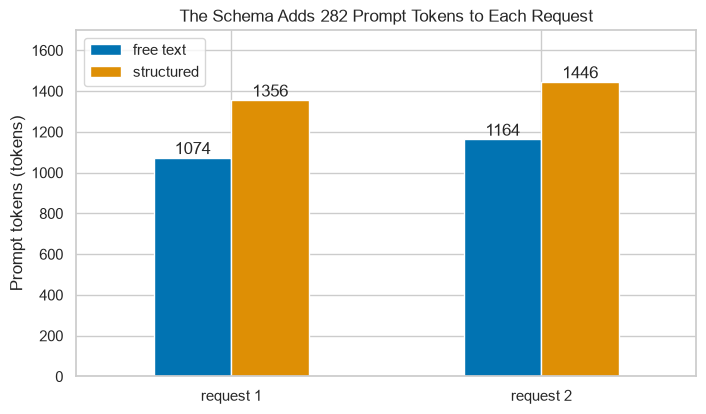

In [23]:
# prompt tokens per request, free text against structured, with what the schema adds
tokens = pd.DataFrame({"free text": [r.usage.prompt_tokens for r in run_free["replies"]],
                       "structured": [r.usage.prompt_tokens for r in run_duration["replies"]]}, index=["request 1", "request 2"])
ax = tokens.plot.bar(rot=0, figsize=(8, 4.5))
for bars in ax.containers:
    ax.bar_label(bars)
ax.set_ylim(0, 1700)
ax.set_ylabel("Prompt tokens (tokens)")
ax.set_title(f"The Schema Adds {tokens['structured'].iloc[0] - tokens['free text'].iloc[0]} Prompt Tokens to Each Request")
plt.show()

The price is Day 1's: the provider's list price for `gpt-4.1-mini`, from [OpenAI's pricing page](https://developers.openai.com/api/docs/pricing), read 2026-10-08.

In [24]:
# each run's tokens in all, its cost in US$ at Day 1's list price, and the prompt tokens the usage marks as cached
PRICE_PER_MILLION = {"prompt": 0.40, "completion": 1.60}


def run_cost(run):
    """A run's prompt and completion tokens in all, and its cost in US$ at the list price."""
    prompt = sum(r.usage.prompt_tokens for r in run["replies"])
    completion = sum(r.usage.completion_tokens for r in run["replies"])
    return prompt, completion, (prompt * PRICE_PER_MILLION["prompt"] + completion * PRICE_PER_MILLION["completion"]) / 1_000_000


for label, run in [("free text", run_free), ("structured", run_duration)]:
    print(label, run_cost(run), "| cached:", [r.usage.prompt_tokens_details.cached_tokens for r in run["replies"]])
print("structured over free text:", round(run_cost(run_duration)[2] / run_cost(run_free)[2], 2))

free text (2238, 125, 0.0010952) | cached: [0, 0]
structured (2802, 194, 0.0014312) | cached: [0, 1280]
structured over free text: 1.31


The saved usage counts 1,280 of the structured run's second-request prompt tokens as cached, and the free run's none.

Every dollar figure here prices all prompt tokens at Day 1's list price.

**On the duration run the schema cost about a third more, and bought a number code can follow.**

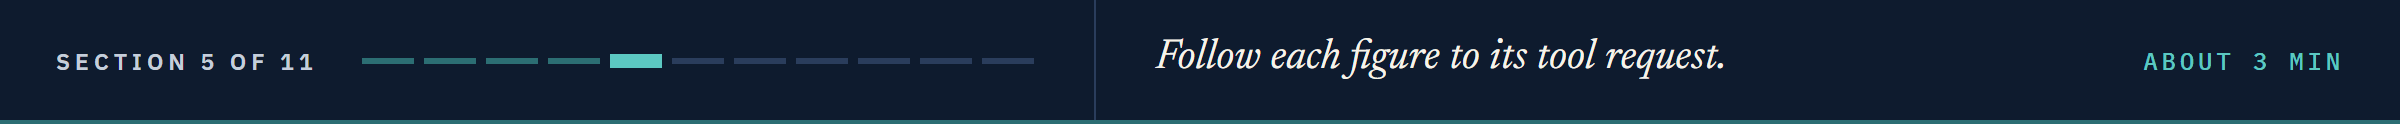

# From a Figure to Its Tool Request

## The DTS Question, Structured

In [25]:
# Day 3's DTS question with ANSWER_FORMAT: each figure and the request it cites
run_dts = agent_loop(client, QUESTIONS["dts"], CHECKED, SCHEMAS, response_format=ANSWER_FORMAT)
answer_dts = DeskAnswer.model_validate_json(run_dts["messages"][-1]["content"])
for figure in answer_dts.figures:
    print(figure.name, "|", figure.value, figure.unit, "|", figure.tool_call_id)

Spread duration in years of bond 99080CAE8 | 4.626971 years | call_aZJqPkMRhYRasET5E8xj7L3a
DTS of bond 99080CAE8 | 680.164737 years_bp | call_YHVs9rrCHdISYTBIf1MIRaqv


In [26]:
# agent answer
print(answer_dts.text)

As of 2026-09-30, the DTS (duration times spread) of bond 99080CAE8, a 7.000% bullet maturing on 2032-06-18, with a yield of 5.606% and an OAS of 147 basis points, is approximately 680.165 years times basis points.


Two figures, each citing a request of its own.

The text states only the DTS, rounded to 680.165; the spread duration is a figure the text never writes.

## The Citations Drawn

In [27]:
# each figure's id and the tool message of the run that carries the same id
results_dts = tool_results(run_dts)
for figure in answer_dts.figures:
    print(figure.tool_call_id, "->", results_dts[figure.tool_call_id])

call_aZJqPkMRhYRasET5E8xj7L3a -> {'spread_duration_years': 4.626971, 'tool_call_id': 'call_aZJqPkMRhYRasET5E8xj7L3a'}
call_YHVs9rrCHdISYTBIf1MIRaqv -> {'dts_years_bp': 680.164737, 'tool_call_id': 'call_YHVs9rrCHdISYTBIf1MIRaqv'}


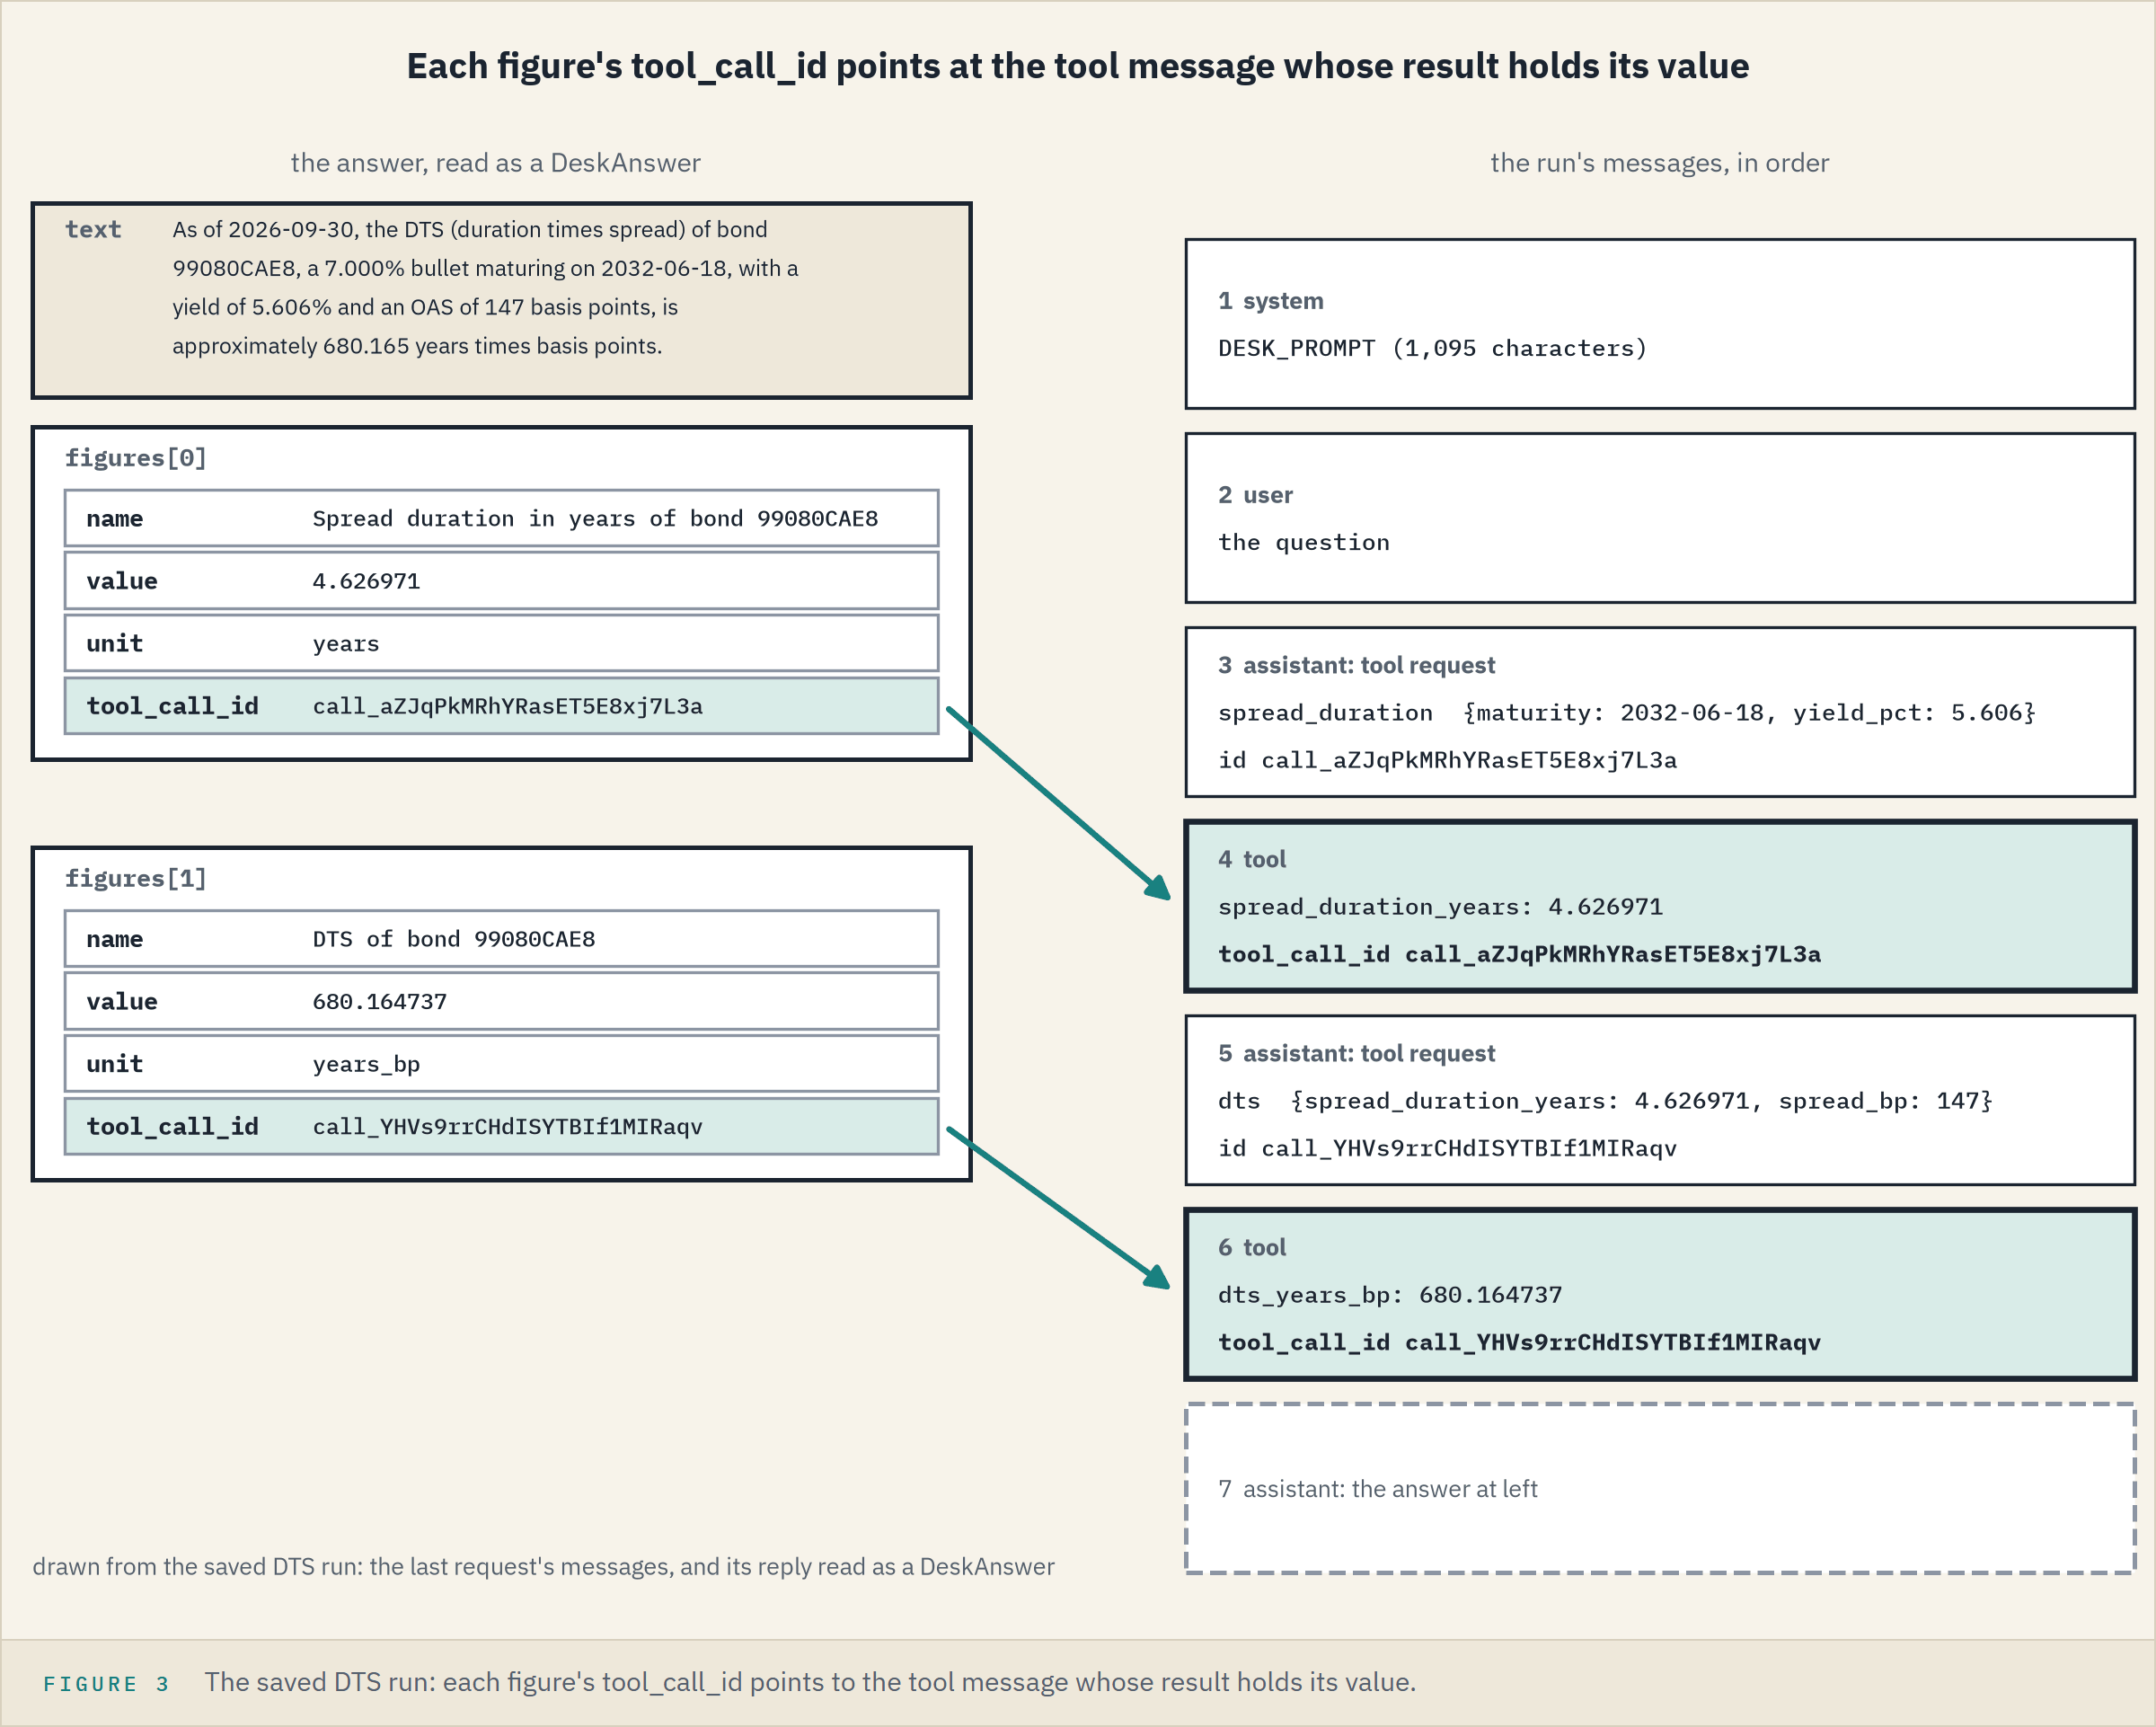

A **pointer diagram** draws each figure as a box of its fields, with an arrow from its `tool_call_id` to the message it names.

Each arrow lands on a tool message whose result holds the figure's value, to the last digit.

### Interpretation of the Pointers

In all three figures so far the id names a tool request of its own run, and the value is the tool's, whole.

The texts round: 2.588, 680.165.

An id is a claim the reply makes; code can follow it.

**A citation is a claim, and code can follow it to the result.**

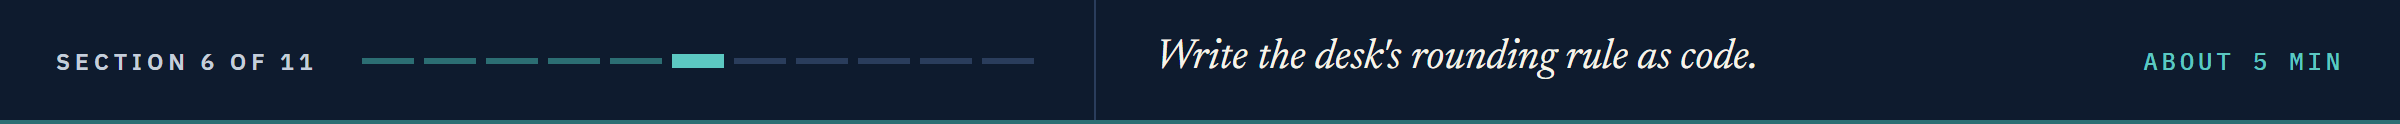

# The Rounding Rule

**Predict 2**

Course 1 taught that `round` sends a tie to the even digit.
2.587515 to 5 decimals is a tie on paper.
Q. What does `round(2.587515, 5)` give? Write down a number.

## Python's `round`

`Decimal(x)` shows the exact binary value a float holds.

In [28]:
# Python's round to 5 decimals, and the value the float really holds
print("round gives", round(2.587515, 5), "| the float holds", Decimal(2.587515))

round gives 2.58751 | the float holds 2.587514999999999787405613460578024387359619140625


`round` works on the binary value, which sits just under the tie, so it rounds down: check your Predict 2.

A desk writing 2.587515 to 5 decimals rounds the tie up, away from zero.

## Half Away From Zero

`repr(x)` is a float's shortest decimal form (Course 1), and `Decimal(repr(x))` keeps that form exactly.
`.quantize(Decimal("0.00001"), rounding=ROUND_HALF_UP)` rounds it to the decimals of `0.00001`, a tie away from zero.

In [29]:
# the same number read from its decimal form, rounded half away from zero to 5 decimals
print(Decimal(repr(2.587515)).quantize(Decimal("0.00001"), rounding=ROUND_HALF_UP))

2.58752


## `rounds_to`

In [30]:
# does a value, rounded half away from zero to the decimals a written number shows, equal that number?
def rounds_to(value, written):
    """True when value, rounded half away from zero to the decimals of written, equals written."""
    return Decimal(repr(value)).quantize(Decimal(written), rounding=ROUND_HALF_UP) == Decimal(written)


WRITINGS = ["2.6", "2.59", "2.588", "2.5875", "2.58752", "2.587515", "2.58751", "2.589"]
print({written: rounds_to(2.587515, written) for written in WRITINGS})

{'2.6': True, '2.59': True, '2.588': True, '2.5875': True, '2.58752': True, '2.587515': True, '2.58751': False, '2.589': False}


Six writings stand for 2.587515 at their decimals; 2.58751 rounds the tie the wrong way, and 2.589 has a wrong digit.

## Where the Two Rules Differ

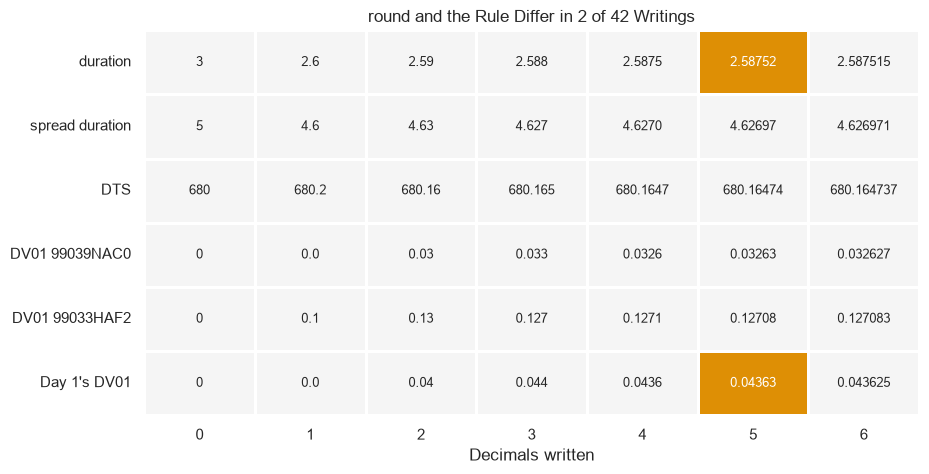

In [31]:
# today's five tool values and Day 1's DV01, written by the rule at 0 to 6 decimals; lit where round gives another number
# Decimal(10) ** -d is 1, 0.1, 0.01, ...: the place to round to
values = {"duration": 2.587515, "spread duration": 4.626971, "DTS": 680.164737, "DV01 99039NAC0": 0.032627,
          "DV01 99033HAF2": 0.127083, "Day 1's DV01": 0.043625}
rule = pd.DataFrame({d: [str(Decimal(repr(v)).quantize(Decimal(10) ** -d, rounding=ROUND_HALF_UP)) for v in values.values()]
                     for d in range(7)}, index=list(values))
differs = pd.DataFrame({d: [Decimal(repr(round(v, d))) != Decimal(rule.loc[k, d]) for k, v in values.items()]
                        for d in range(7)}, index=list(values))
ax = sns.heatmap(differs.astype(int), annot=rule, fmt="", cbar=False, cmap=["whitesmoke", sns.color_palette()[1]],
                 linewidths=1, annot_kws={"fontsize": 9})
ax.set_xlabel("Decimals written")
ax.set_title(f"round and the Rule Differ in {int(differs.values.sum())} of {differs.size} Writings")
plt.show()

Each cell is the rule's writing; the two lit cells are ties at 5 decimals where `round` gives the digit below.

## Your Turn: Write the Figure

Choose a writing: the grey band is every value that rounds to it, and the dot is the tool's 2.587515.

In [32]:
# your turn: choose a written figure and see whether the tool's value rounds to it
def figure_view(written="2.588"):
    """Draw the band of values that round to written, in units of its last decimal, and the tool's 2.587515."""
    decimals = len(written.split(".")[1])
    offset = (2.587515 - float(written)) * 10.0 ** decimals
    fig, ax = plt.subplots(figsize=(9, 2.6))
    ax.hlines(0, -0.5, 0.5, lw=18, color="lightgrey", label=f"values that round to {written}")
    ax.scatter(offset, 0, s=90, zorder=3, label="the tool's 2.587515")
    ax.set_xlim(-2, 2)
    ax.set_yticks([])
    ax.set_xlabel("Tool value minus the written figure (units of its last decimal)")
    ax.set_title(f"{written}: rounds_to gives {rounds_to(2.587515, written)}")
    ax.legend(loc="upper left", ncols=2)
    plt.show()


interact(figure_view, written=WRITINGS);

interactive(children=(Dropdown(description='written', index=2, options=('2.6', '2.59', '2.588', '2.5875', '2.5…

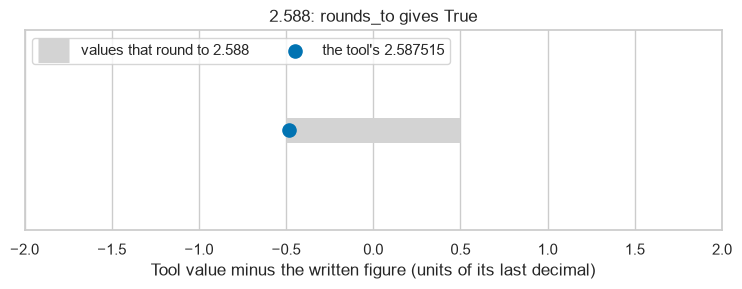

In [33]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
figure_view("2.588")

A value exactly on the band's right edge is a tie, and rounds up and out: choose 2.58751.

**A figure passes when the tool's value, rounded half away from zero to the figure's decimals, is the figure.**

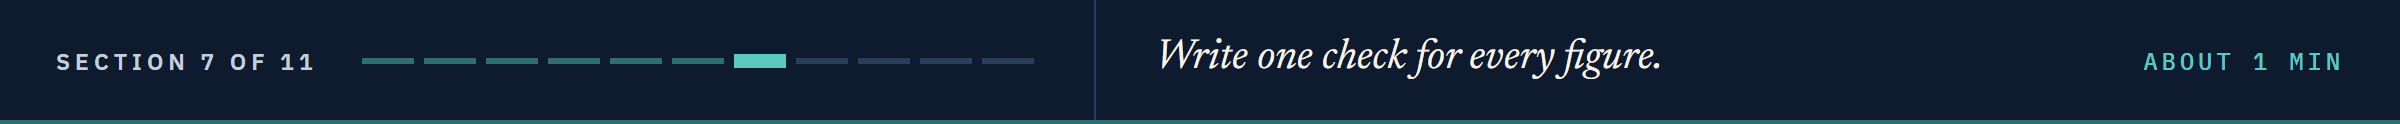

# The Figure Check

## `check_figures`

The check asks three things of each figure: is its tool request in the run, does a number in that result round to it, and does that number's key end in its unit.

In [34]:
# one row a figure: cited, value_matches, unit_matches, and passed only if all three hold
def check_figures(answer, run):
    """One row per figure: its request in the run, a number there that rounds to it, that key ending in its unit."""
    results = tool_results(run)
    rows = []
    for figure in answer.figures:
        result = results.get(figure.tool_call_id, {})
        # the keys whose number rounds to the figure (floats only: an error result or an id is text)
        keys = [key for key, value in result.items() if isinstance(value, float) and rounds_to(value, repr(figure.value))]
        rows.append({"name": figure.name, "value": figure.value, "unit": figure.unit,
                     "cited": figure.tool_call_id in results, "value_matches": len(keys) > 0,
                     "unit_matches": any(key.endswith("_" + figure.unit) for key in keys)})
    table = pd.DataFrame(rows)
    table["passed"] = table["cited"] & table["value_matches"] & table["unit_matches"]
    return table

## Every Figure So Far

In [35]:
# the duration and DTS answers' figures through the check
so_far = pd.concat([check_figures(answer_duration, run_duration), check_figures(answer_dts, run_dts)], ignore_index=True)
print(int(so_far["passed"].sum()), "of", len(so_far), "pass")
so_far

3 of 3 pass


,name,value,unit,cited,value_matches,unit_matches,passed
0,Modified duration of bond 99126WAE0,2.587515,years,True,True,True,True
1,Spread duration in years of bond 99080CAE8,4.626971,years,True,True,True,True
2,DTS of bond 99080CAE8,680.164737,years_bp,True,True,True,True


No judgement and no reading of the text: an id, a number and a key.

**A check is worth something only if it can fail.**

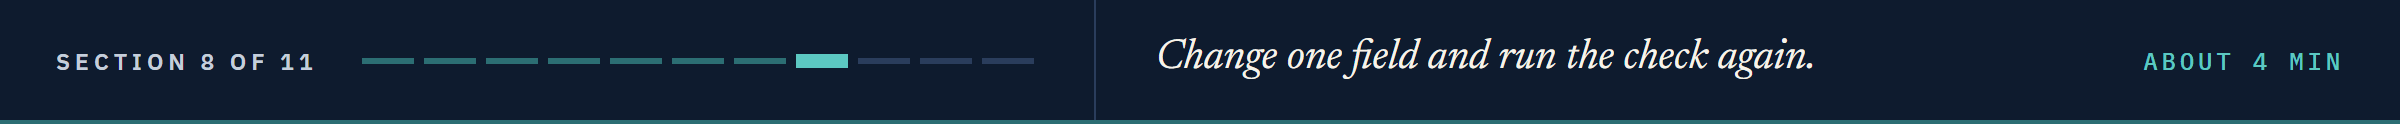

# Breaking the Check on Purpose

## One Digit Changed

`answer.model_copy(deep=True)` copies a model and every model inside it, so a change to the copy leaves the saved answer as it was.

In [36]:
# a copy of the duration answer with its figure's last digit changed
one_digit = answer_duration.model_copy(deep=True)
one_digit.figures[0].value = 2.587516
check_figures(one_digit, run_duration)

,name,value,unit,cited,value_matches,unit_matches,passed
0,Modified duration of bond 99126WAE0,2.587516,years,True,False,False,False


The request is still cited; no number in its result rounds to 2.587516, so no key is left to match the unit.

## A Citation the Run Does Not Hold

In [37]:
# a copy whose figure cites an id no tool request of the run carries
no_request = answer_duration.model_copy(deep=True)
no_request.figures[0].tool_call_id = "call_not_in_this_run"
check_figures(no_request, run_duration)

,name,value,unit,cited,value_matches,unit_matches,passed
0,Modified duration of bond 99126WAE0,2.587515,years,False,False,False,False


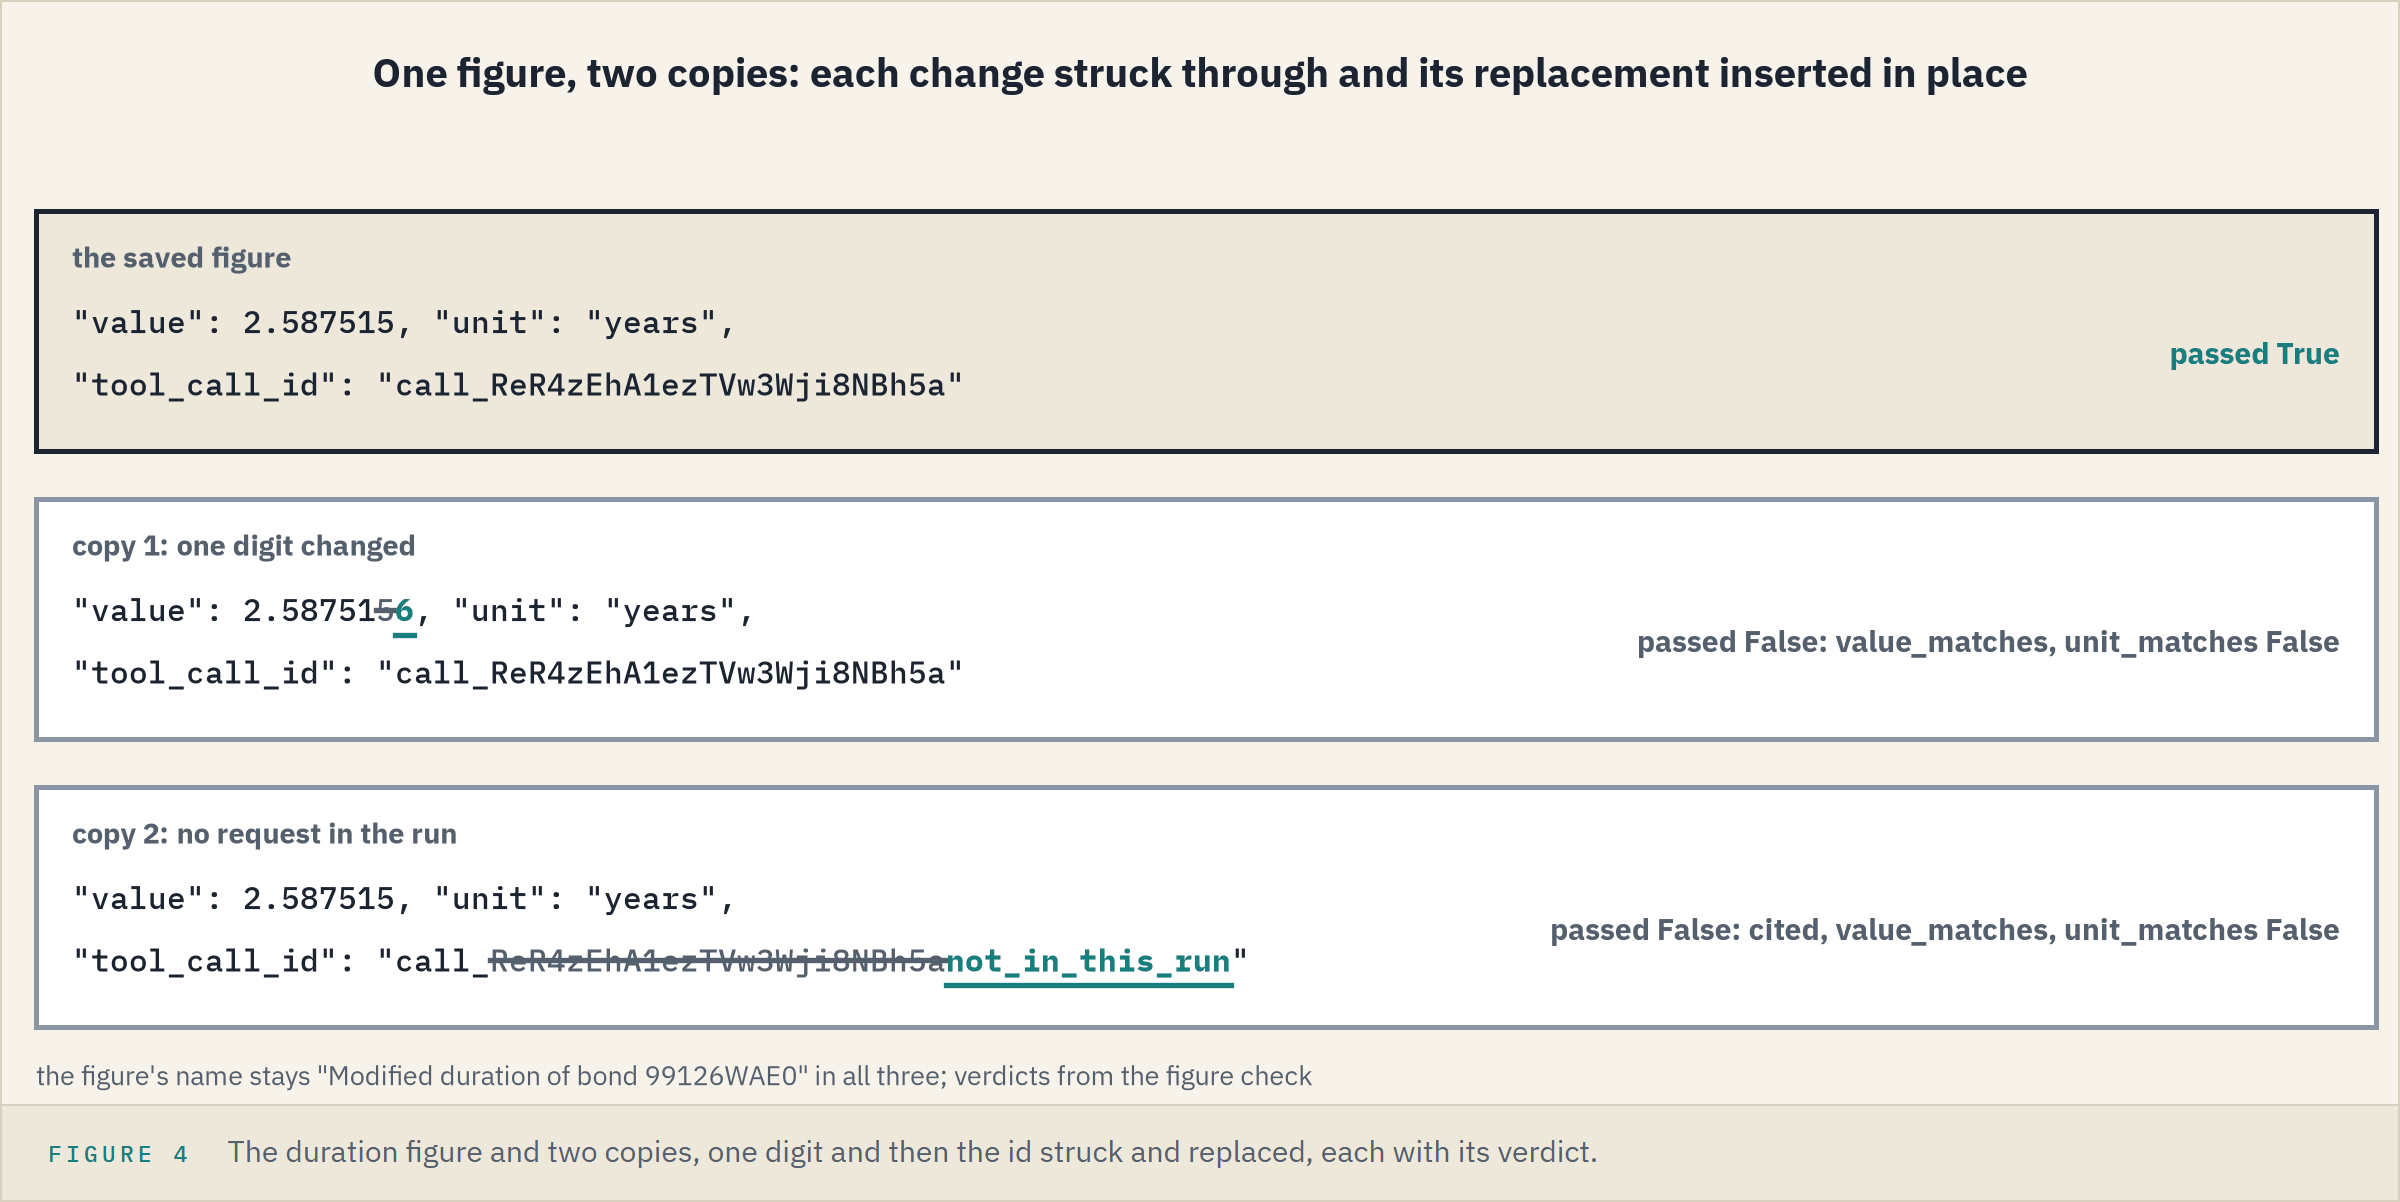

Course 7's Day 13 redline, on one figure: the saved figure passes, and each one-place change fails.

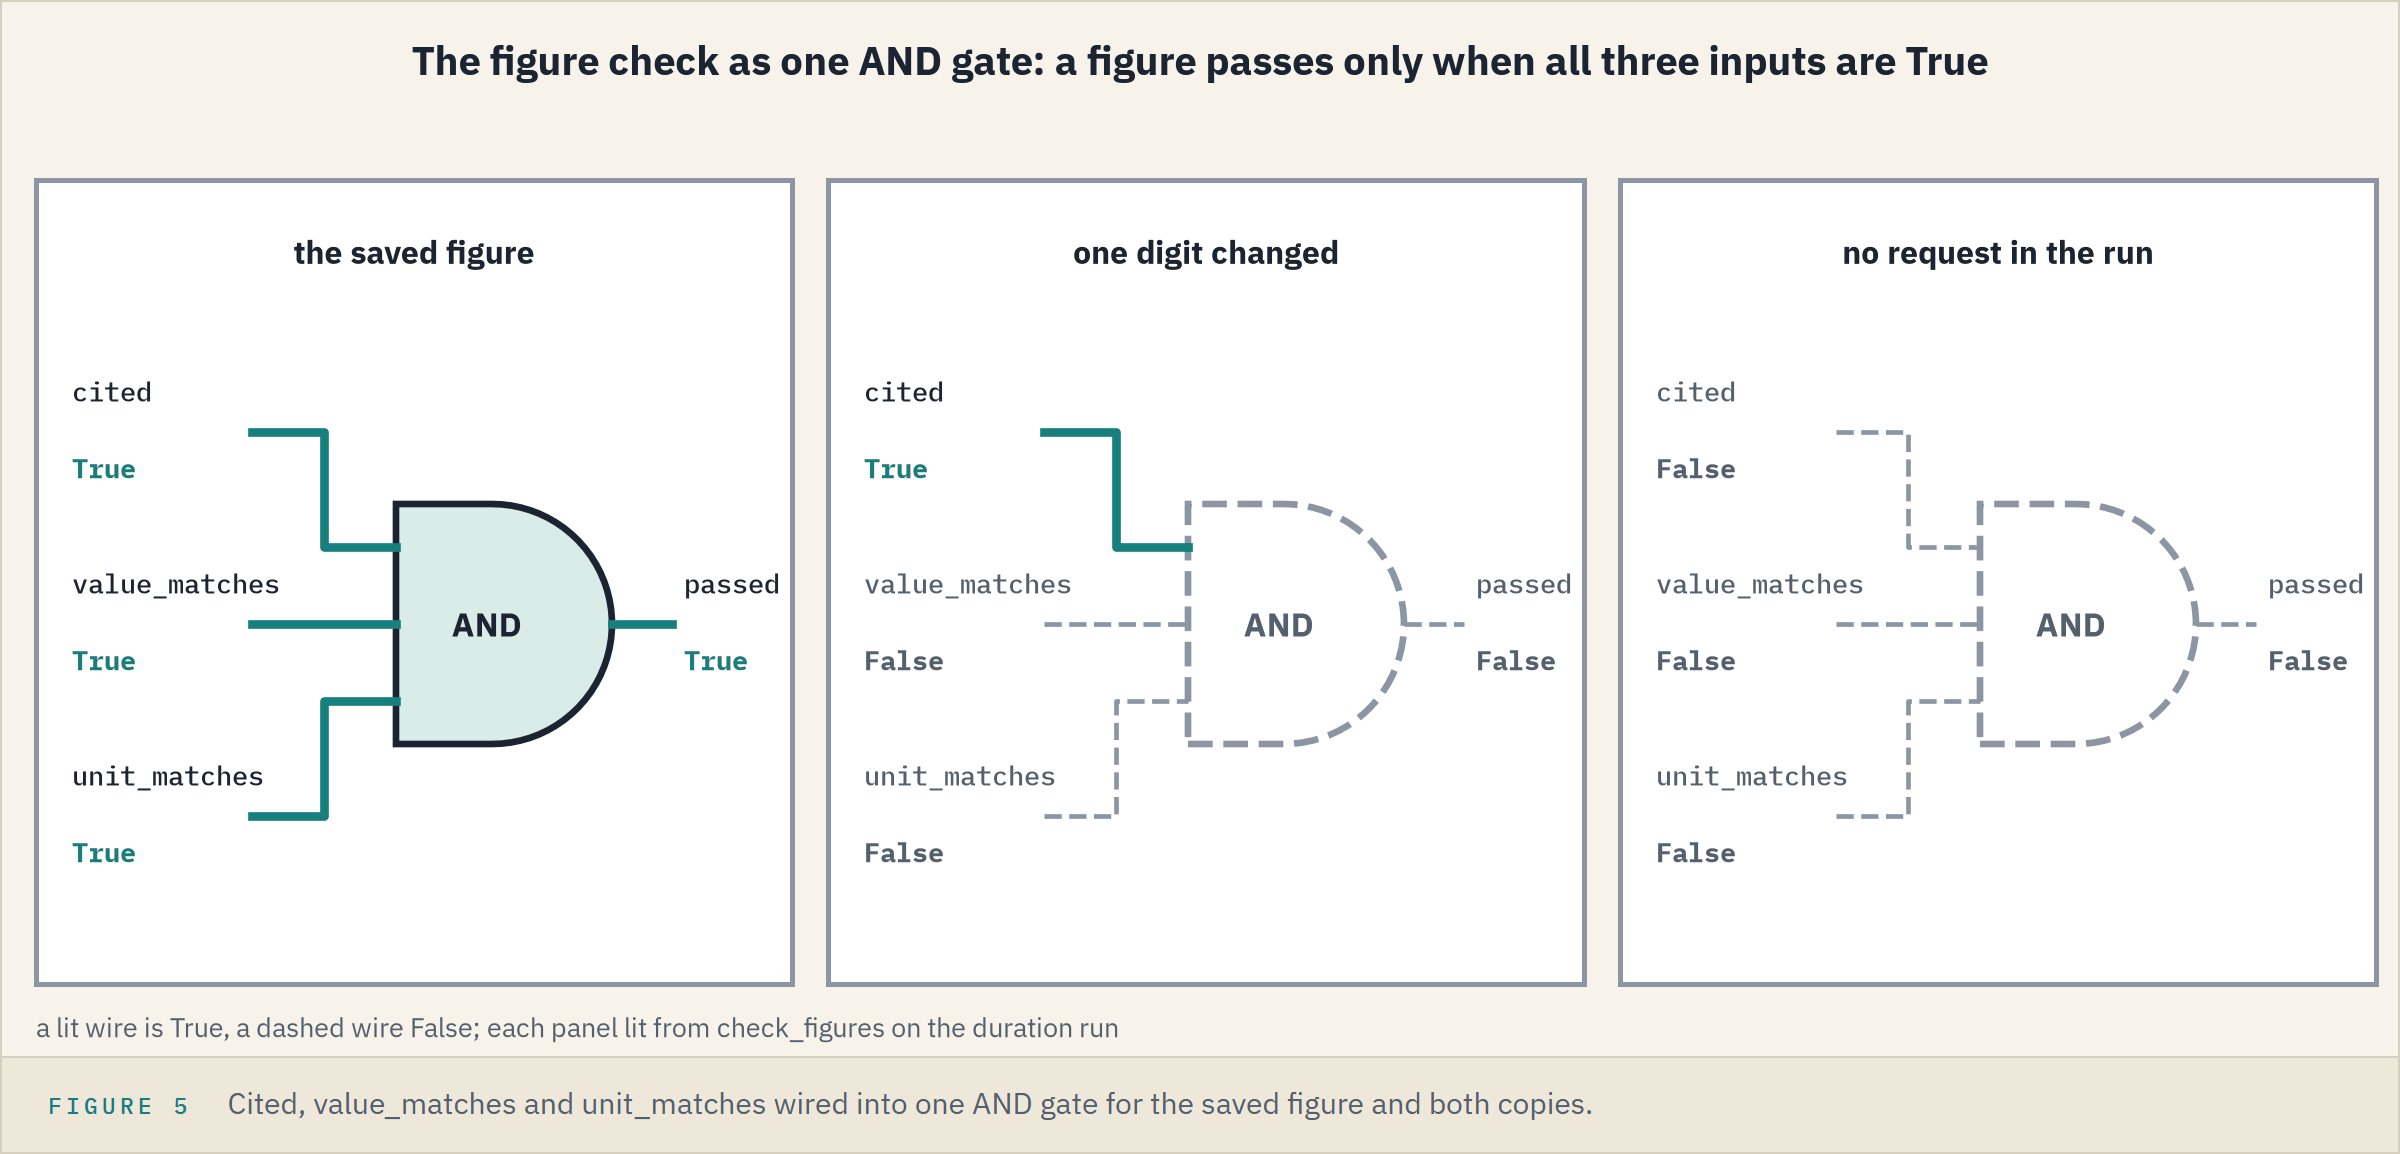

A **logic gate diagram** wires the check's three inputs into one AND gate: one dashed input and `passed` is False.

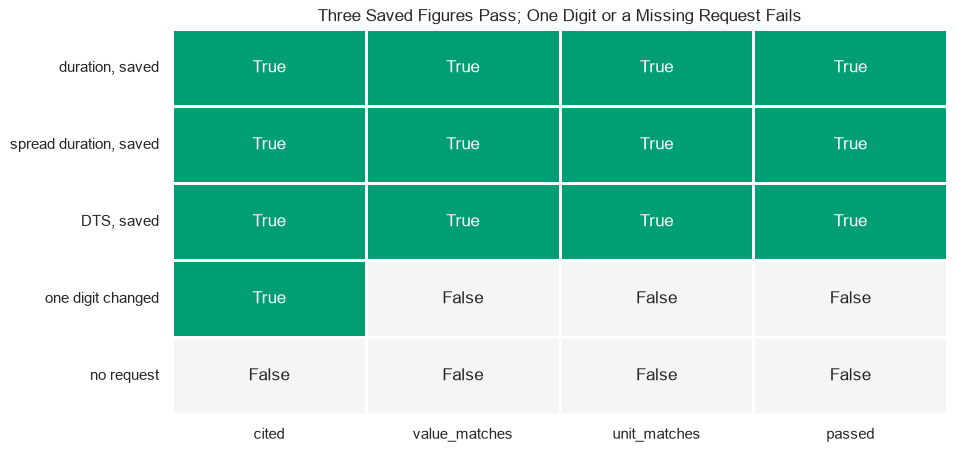

In [38]:
# the three saved figures and the two copies by the check's four columns
grid = pd.concat([so_far, check_figures(one_digit, run_duration), check_figures(no_request, run_duration)], ignore_index=True)
grid.index = ["duration, saved", "spread duration, saved", "DTS, saved", "one digit changed", "no request"]
columns = ["cited", "value_matches", "unit_matches", "passed"]
ax = sns.heatmap(grid[columns].astype(int), annot=grid[columns].astype(str), fmt="", cbar=False,
                 cmap=["whitesmoke", sns.color_palette()[2]], linewidths=1)
ax.set_title("Three Saved Figures Pass; One Digit or a Missing Request Fails")
plt.show()

**The check fails a wrong digit and a request the run never sent.**

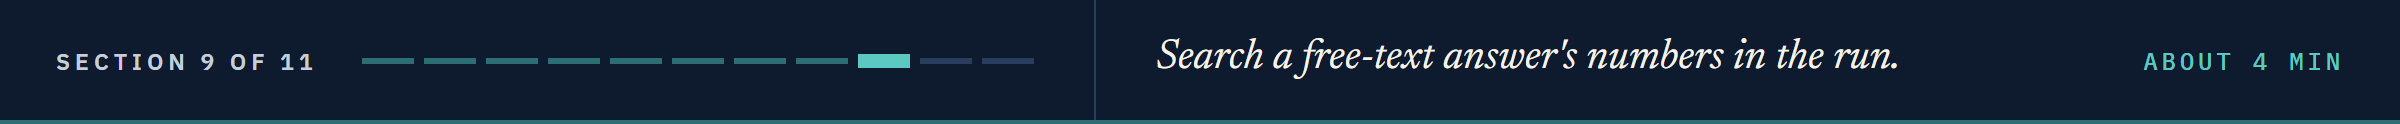

# Checking Free Text

## `numbers_untraced`

A free-text answer has no ids, so its numbers can only be searched for: in the question, or in any tool result of the run at their rounding.

In [39]:
# the numbers of a text that the question does not write and no tool result of the run rounds to
def numbers_untraced(text, run):
    """The numbers of a text that the question does not write and no tool result of the run rounds to."""
    asked = re.findall(NUMBER, run["messages"][1]["content"])
    values = [v for result in tool_results(run).values() for v in result.values() if isinstance(v, float)]
    return [n for n in re.findall(NUMBER, text) if n not in asked and not any(rounds_to(v, n) for v in values)]


print("as saved:", numbers_untraced(free_answer, run_free), "| 2.588 changed to 2.589:",
      numbers_untraced(free_answer.replace("2.588", "2.589"), run_free))

as saved: [] | 2.588 changed to 2.589: ['2.589']


A number passes if any result of the run rounds to it; only a citation says which.

## Day 3's OAS Answer, Checked

In [40]:
# check-fails: numbers
# Day 3's saved exchange for its OAS question (its Exercise 2): no tool request, so its run is the two messages it sent
day3_oas = pd.read_json(DATA + "course8_agent_runs/day03/be6b485b162a8867c32debcf8d609440bfc0a551ada5da631ff914a74f1e704d.json", typ="series")
run_day3_oas = {"messages": day3_oas["request"]["messages"]}
answer_day3_oas = day3_oas["response"]["choices"][0]["message"]["content"]
print(answer_day3_oas)
print("untraced:", numbers_untraced(answer_day3_oas, run_day3_oas))

The option-adjusted spread (OAS) in basis points (bp) of bond 99080CAE8 is 147 bp as of 2026-09-30. This is found in the synthetic holdings data for the bond with a 7.000% coupon, settling 2026-09-30, maturing 2032-06-18, and a yield of 5.606%. 

This information is from section 1.
untraced: ['147', '1']


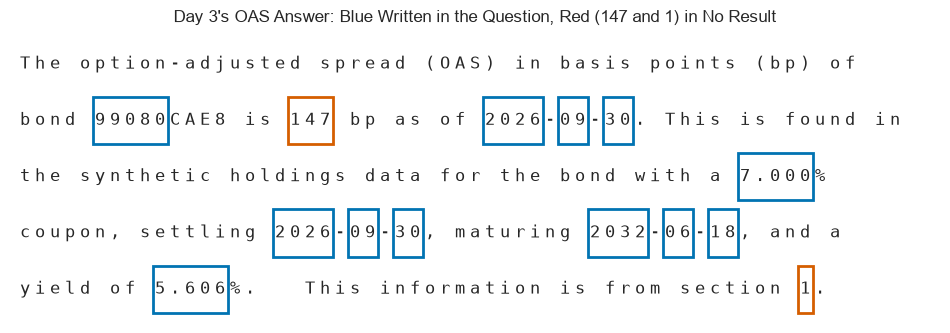

In [41]:
# the same answer boxed: blue if the question wrote the number, red if not
boxed(answer_day3_oas, re.findall(NUMBER, run_day3_oas["messages"][1]["content"]), "Day 3's OAS Answer: Blue Written in the Question, Red (147 and 1) in No Result")

147 is the file's `oas` for 99080CAE8 and the `dts` description's example (Day 3), and in no tool result.

**Predict 3**

Day 3's free-text OAS answer stated 147 bp, which no tool returned, and no tool returns a spread.
Q. Asked again with `ANSWER_FORMAT`, how many figures does the saved answer hold, and is one of them an OAS?

## The Same Question, Structured

In [42]:
# the OAS question with ANSWER_FORMAT: each tool request and the result that came back
run_oas = agent_loop(client, QUESTIONS["oas"], CHECKED, SCHEMAS, response_format=ANSWER_FORMAT)
for message in run_oas["messages"][2:-1]:
    print(message["role"], "|", message["content"] or message["tool_calls"][0]["function"]["name"] + " " + message["tool_calls"][0]["function"]["arguments"])

assistant | dts {"spread_duration_years":0,"spread_bp":0}
tool | {"error": "dts needs a spread duration and a spread, not 0.0 years and 0.0 bp: a 0 means an input was not given", "tool_call_id": "call_yIfwkj8f3hpnKWdtIRUwORkp"}
assistant | spread_duration {"settlement":"2026-09-30","maturity":"2032-06-18","coupon_pct":7,"yield_pct":5.606}
tool | {"spread_duration_years": 4.626971, "tool_call_id": "call_TbcOAwoBji3sHhwR51MlJzGF"}
assistant | dts {"spread_duration_years":4.626971,"spread_bp":0}
tool | {"error": "dts needs a spread duration and a spread, not 4.626971 years and 0.0 bp: a 0 means an input was not given", "tool_call_id": "call_tqlFWPpiNxqK0Ozb2mPaowxj"}


In [43]:
# agent answer
answer_oas = DeskAnswer.model_validate_json(run_oas["messages"][-1]["content"])
print(answer_oas.text)

The option-adjusted spread (OAS) in basis points (bp) for bond 99080CAE8 is not directly provided in the text. However, the spread duration of the bond is 4.627 years. To calculate the OAS, the spread in basis points is needed, which is not given in the text.


In [44]:
# its figures through the check, and its text's numbers searched
print(len(run_oas["replies"]), "requests | untraced in the text:", numbers_untraced(answer_oas.text, run_oas))
check_figures(answer_oas, run_oas)

4 requests | untraced in the text: []


,name,value,unit,cited,value_matches,unit_matches,passed
0,Spread duration of bond 99080CAE8,4.626971,years,True,True,True,True


### Interpretation of the OAS Run

The replies named `dts` twice, each time with a spread of 0, and `dts` returned an error result each time.

The answer states no OAS; its one figure, the spread duration, passes, and its text's 4.627 traces: check your Predict 3.

One saved run does not show why it differs from Day 3's.

**Asked for a structure, the saved OAS answer stated no spread it could not cite.**

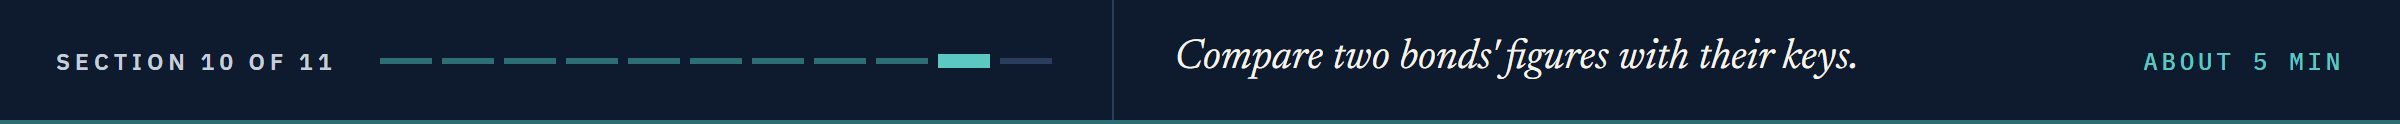

# Two Bonds in One Question

## Two DV01s

In [45]:
# the two-bond DV01 question with ANSWER_FORMAT, and its figures through the check
run_two = agent_loop(client, QUESTIONS["two"], CHECKED, SCHEMAS, response_format=ANSWER_FORMAT)
answer_two = DeskAnswer.model_validate_json(run_two["messages"][-1]["content"])
check_figures(answer_two, run_two)

,name,value,unit,cited,value_matches,unit_matches,passed
0,DV01 of bond 99039NAC0,0.032627,per_100,True,True,True,True
1,DV01 of bond 99033HAF2,0.127083,per_100,True,True,True,True


**Predict 4**

In a copy, swap the two figures' values and their ids, and keep their names, so each figure names one bond and cites the other's request.
Q. How many of the two figures pass `check_figures`?

## Swapping Two Figures

In [46]:
# a copy with the two figures' values and ids swapped, names kept
swapped = answer_two.model_copy(deep=True)
first, second = swapped.figures
first.value, second.value = second.value, first.value
first.tool_call_id, second.tool_call_id = second.tool_call_id, first.tool_call_id
table_swapped = check_figures(swapped, run_two)
print("swapped:", int(table_swapped["passed"].sum()), "of", len(table_swapped), "pass")
table_swapped

swapped: 2 of 2 pass


,name,value,unit,cited,value_matches,unit_matches,passed
0,DV01 of bond 99039NAC0,0.127083,per_100,True,True,True,True
1,DV01 of bond 99033HAF2,0.032627,per_100,True,True,True,True


Each cited request is in the run, and its value and unit match: the check never reads the name.

## Against the Answer Keys

In [47]:
# each swapped figure against the key for the bond its name states
DV01_KEYS = {"99039NAC0": KEYS["DV01 99039NAC0"], "99033HAF2": KEYS["DV01 99033HAF2"]}
for figure in swapped.figures:
    print(figure.name, "|", figure.value, "against the key", DV01_KEYS[figure.name.split()[-1]])

DV01 of bond 99039NAC0 | 0.127083 against the key 0.032627
DV01 of bond 99033HAF2 | 0.032627 against the key 0.127083


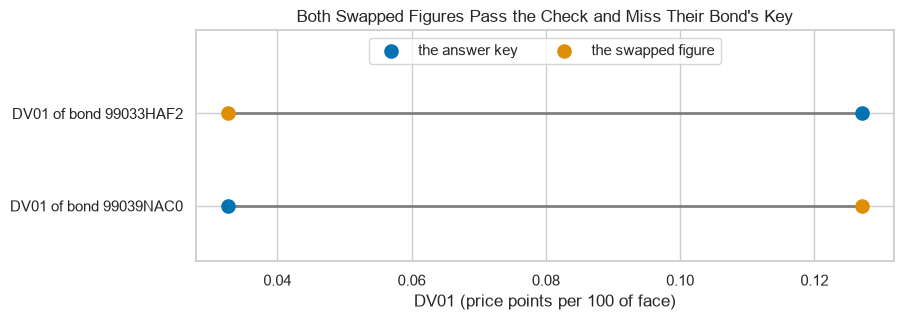

In [48]:
# a dumbbell: each figure's value and its bond's key on one line
fig, ax = plt.subplots(figsize=(9, 3))
for row, figure in enumerate(swapped.figures):
    key = DV01_KEYS[figure.name.split()[-1]]
    ax.plot([key, figure.value], [row, row], color="grey", lw=2, zorder=1)
    ax.scatter(key, row, s=90, color=sns.color_palette()[0], zorder=2, label="the answer key" if row == 0 else None)
    ax.scatter(figure.value, row, s=90, color=sns.color_palette()[1], zorder=2, label="the swapped figure" if row == 0 else None)
ax.set_yticks([0, 1], [figure.name for figure in swapped.figures])
ax.set_ylim(-0.6, 1.9)
ax.set_xlabel("DV01 (price points per 100 of face)")
ax.set_title("Both Swapped Figures Pass the Check and Miss Their Bond's Key")
ax.legend(loc="upper center", ncols=2)
plt.show()

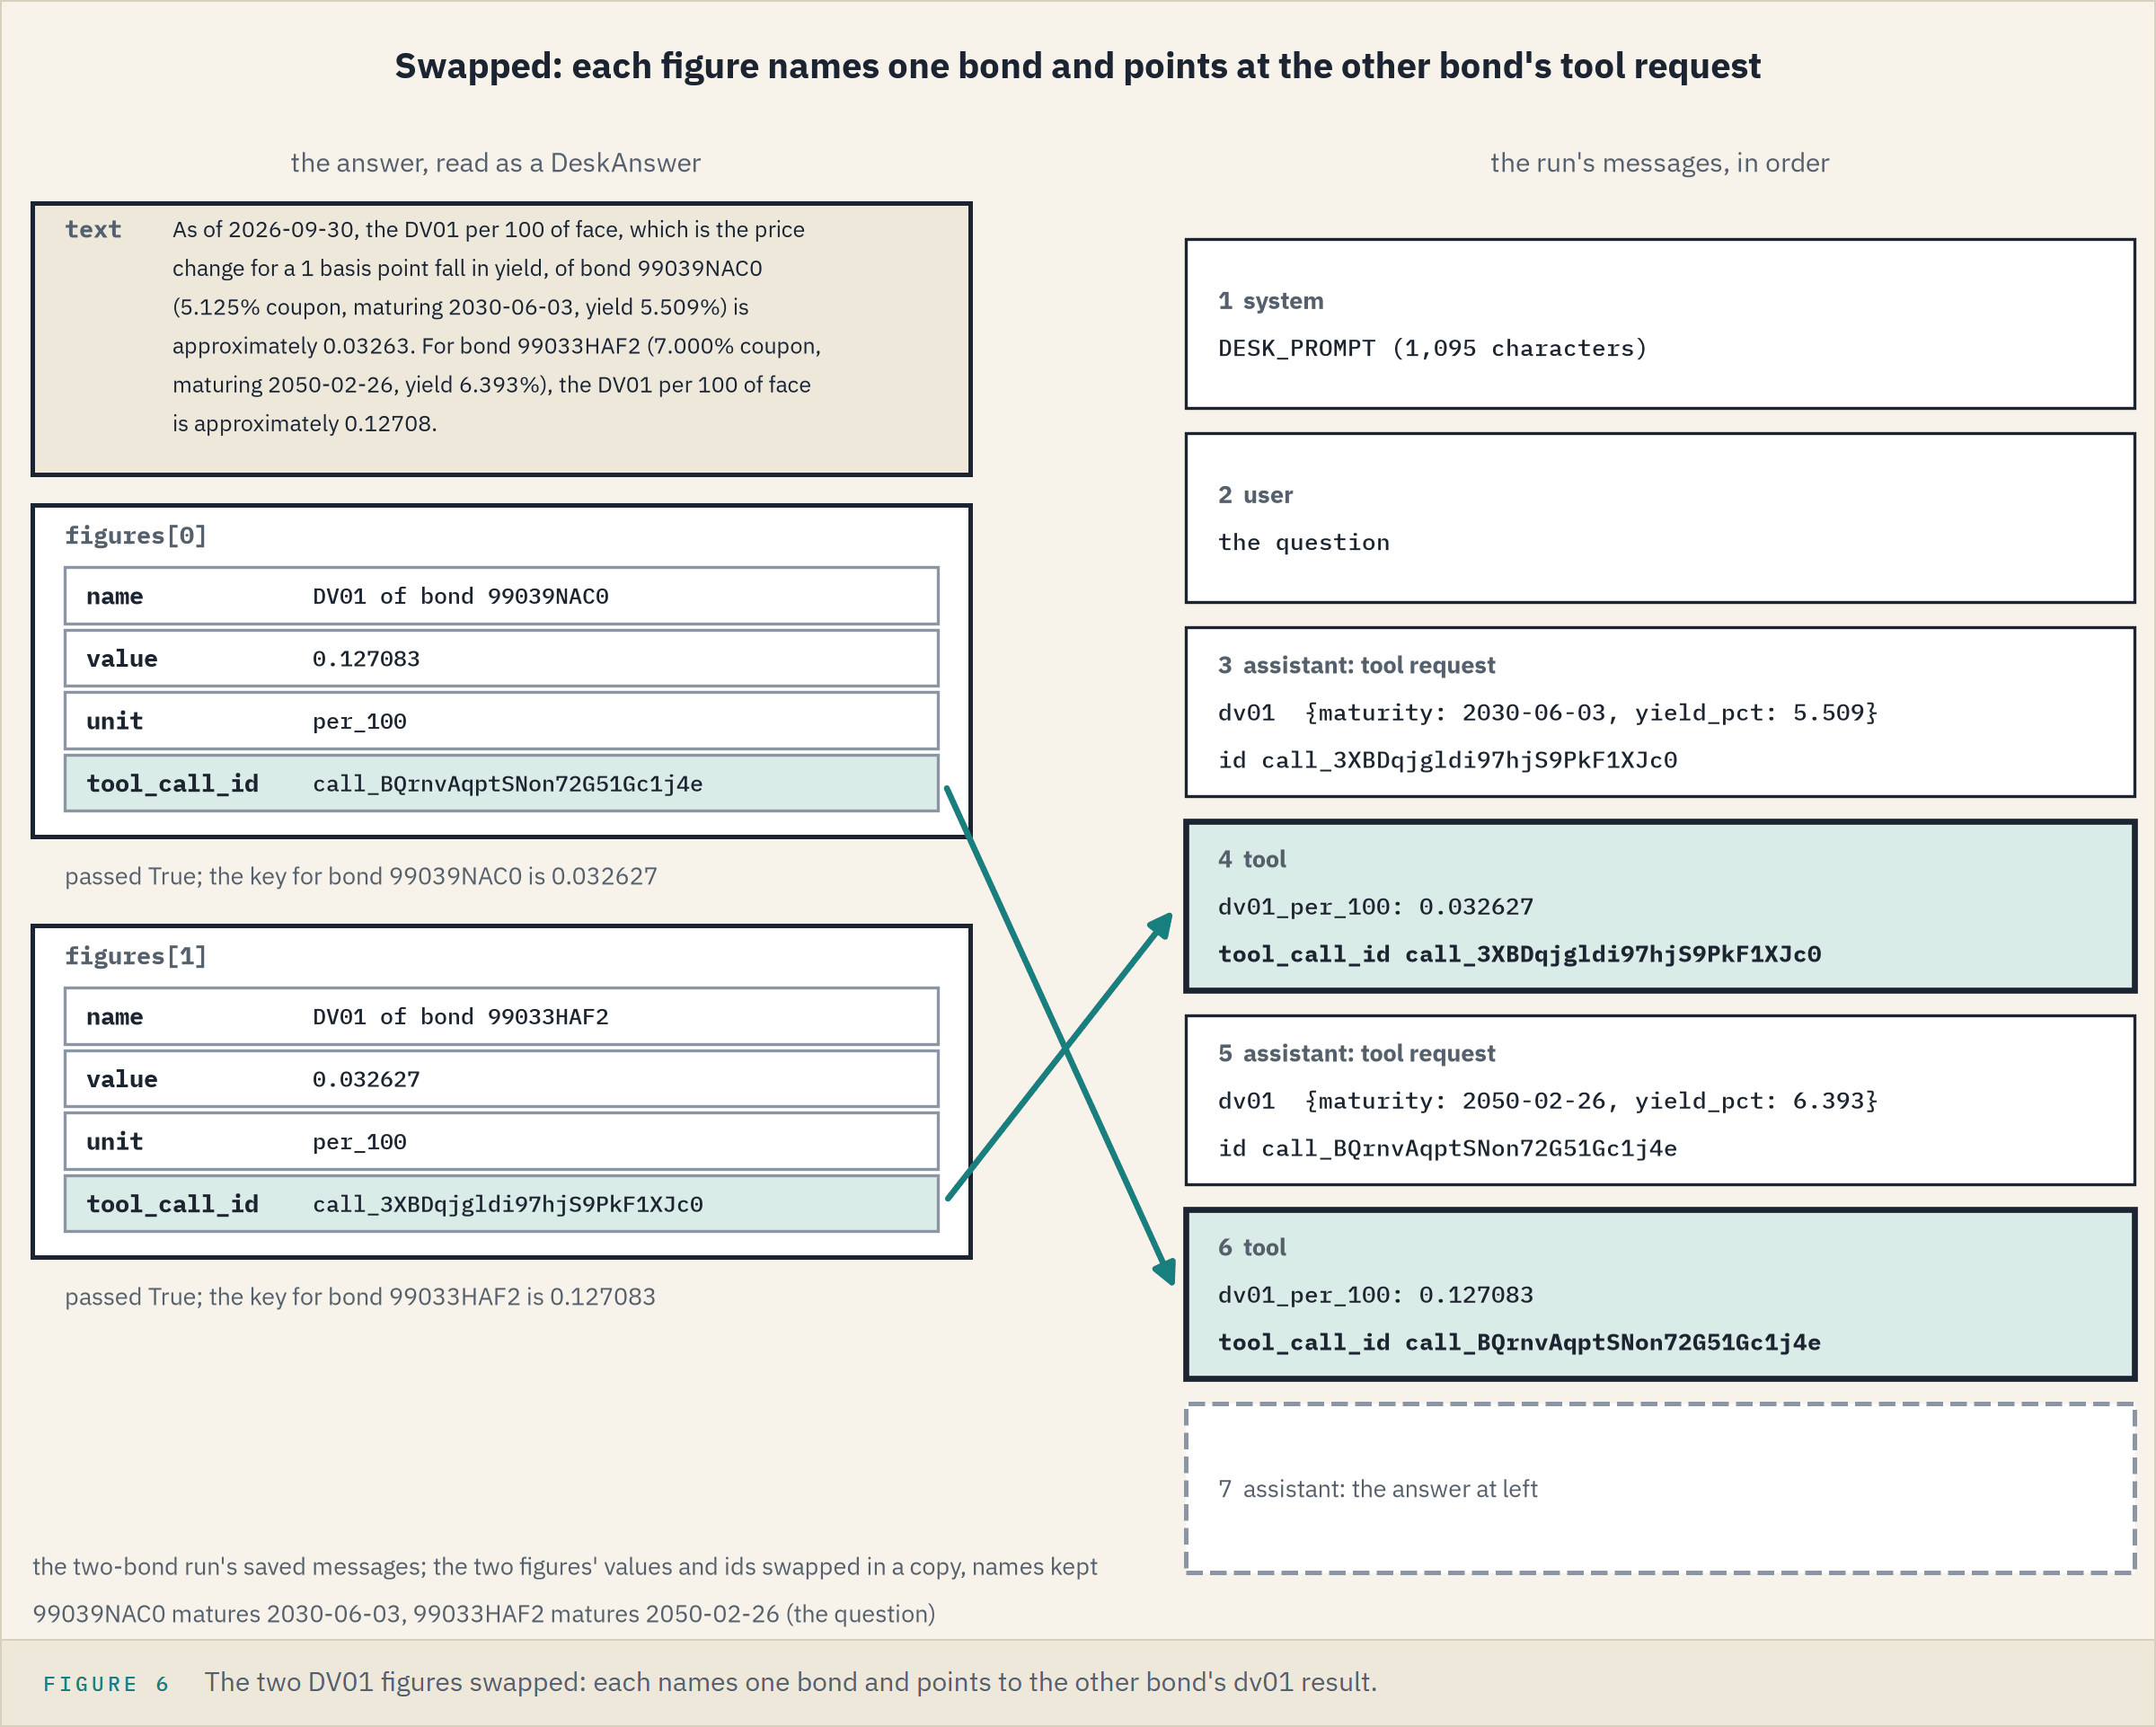

### Interpretation of the Swap

A right tool on the wrong bond passes every check here.

Only the keys, decided before any request, catch it; Day 13 runs answers against keys.

## Today's Runs Side by Side

In [49]:
# today's five runs: requests, tokens and US$ at Day 1's list price
rows = []
for name, run in [("free", run_free), ("duration", run_duration), ("DTS", run_dts), ("OAS", run_oas), ("two DV01s", run_two)]:
    prompt, completion, usd = run_cost(run)
    rows.append({"run": name, "requests": len(run["replies"]), "prompt_tokens": prompt, "completion_tokens": completion, "usd": usd})
today = pd.DataFrame(rows).set_index("run")
print(today[["requests", "prompt_tokens", "completion_tokens"]].sum().to_dict(), "| US$", round(today["usd"].sum(), 7))
today

{'requests': 14, 'prompt_tokens': 19763, 'completion_tokens': 1131} | US$ 0.0097148


,requests,prompt_tokens,completion_tokens,usd
run,,,,
free,2,2238,125,0.001095
duration,2,2802,194,0.001431
DTS,3,4324,260,0.002146
OAS,4,5912,225,0.002725
two DV01s,3,4487,327,0.002318


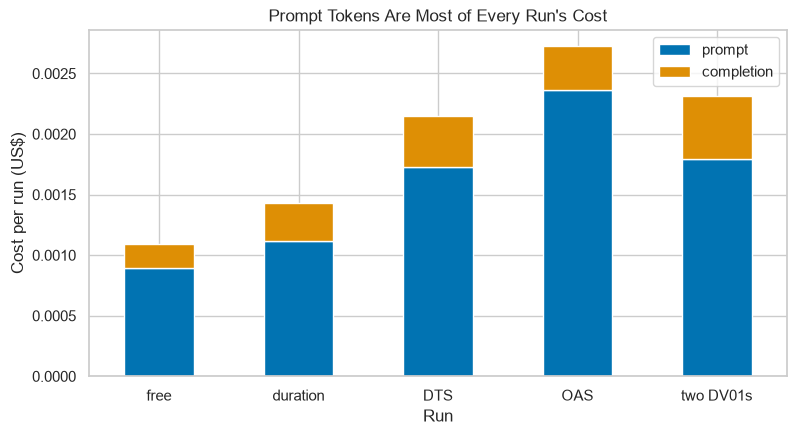

In [50]:
# each run's US$, prompt and completion stacked
usd = pd.DataFrame({"prompt": today["prompt_tokens"] * PRICE_PER_MILLION["prompt"] / 1_000_000,
                    "completion": today["completion_tokens"] * PRICE_PER_MILLION["completion"] / 1_000_000})
ax = usd.plot.bar(stacked=True, rot=0, figsize=(9, 4.5))
ax.set_ylabel("Cost per run (US$)")
ax.set_xlabel("Run")
ax.set_title("Prompt Tokens Are Most of Every Run's Cost")
plt.show()

The five runs cost under a cent in all, at the list price.

**Trace every number to its request, then check it against a key.**

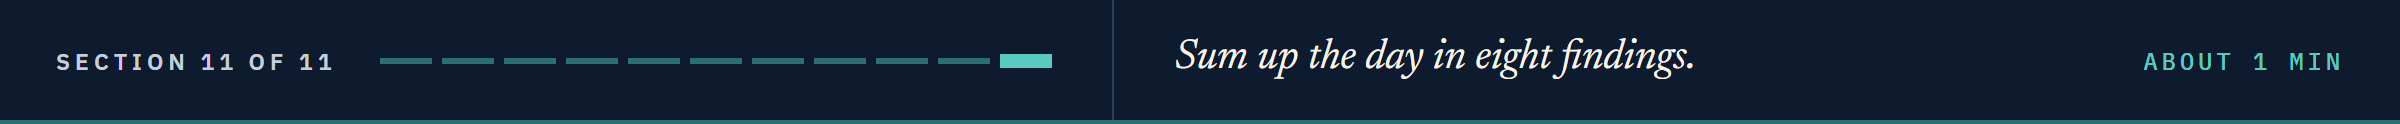

# Insights and Conclusion

Day 1's number check cannot say which request a number came from.

The schema added 282 prompt tokens to each request of the duration run, and about a third to its cost.

Every saved figure writes the tool's value whole and cites a request of its own run; the texts round.

`round` and the half-away rule differ on 2 of 42 writings.

The figure check fails a wrong digit and a request the run never sent.

Free text can be searched, not followed.

Asked for a structure, the saved OAS answer stated no OAS.

Swapped figures pass the check and miss the keys.

**A figure that cites its request can be checked by code; a key says whether it is the right one.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Describe an answer as a pydantic model and ask for it with a strict `response_format`.
* Read a structured reply into the model, and follow each figure to the tool request it cites.
* Round a number half away from zero to a written number's decimals.
* Write a figure check, and break it on purpose.
* Search a free-text answer for numbers no question or result holds.
* Compare figures with answer keys decided first, and measure what a schema costs.

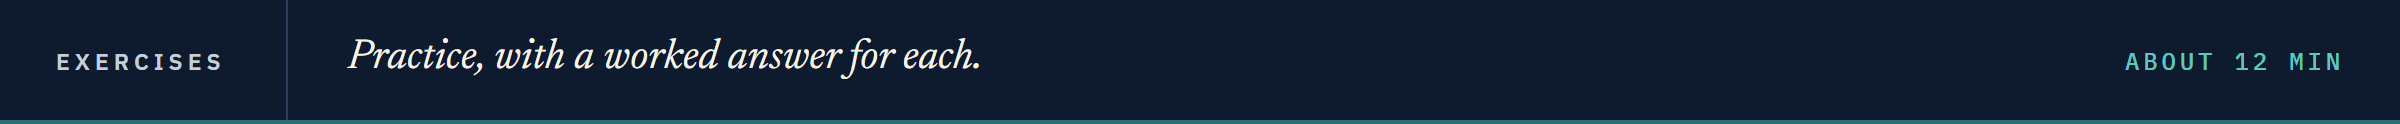

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [51]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Day 3's DTS Answer, Written as Figures**

Day 3's free-text DTS answer is read below from its saved exchange.
Q. Run `numbers_untraced` on it.
Then write its two numbers as a `DeskAnswer` by hand: 680.165 in `years_bp` and 4.627 in `years`, each citing the id its tool's result carries.
Store the number of untraced numbers and the number of figures that pass `check_figures`, as a list, in `ex1_run`.

In [52]:
# agent answer
# Day 3's saved exchange for its DTS question: its last request holds the run's messages, its response the answer
day3_dts = pd.read_json(DATA + "course8_agent_runs/day03/219091039195904d392178f4c45eb5d51c8b497ae4a51a4fe7d5eabb8f150ff4.json", typ="series")
run_day3_dts = {"messages": day3_dts["request"]["messages"]}
answer_day3_dts = day3_dts["response"]["choices"][0]["message"]["content"]
print(answer_day3_dts)
print(tool_results(run_day3_dts))

# your code here
ex1_run = ...

As of 2026-09-30, the DTS (duration times spread) of bond 99080CAE8, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp, is approximately 680.165 years times basis points. The spread duration in years is approximately 4.627.
{'call_RtyKLWwHoj6bYlggE8UPAihf': {'spread_duration_years': 4.626971, 'tool_call_id': 'call_RtyKLWwHoj6bYlggE8UPAihf'}, 'call_4Bfb4qYtc8O7ybKyX6iMasji': {'dts_years_bp': 680.164737, 'tool_call_id': 'call_4Bfb4qYtc8O7ybKyX6iMasji'}}


In [53]:
check("Exercise 1 the untraced numbers and the figures that pass", ex1_run, [0, 2])

Exercise 1 the untraced numbers and the figures that pass: not attempted yet


### Exercise 2

**A Figure in the Wrong Unit**

Q. Copy `answer_dts`, set its first figure's unit to `"pct"`, and run `check_figures` on the copy.
Store that row's `cited`, `unit_matches` and `passed`, as a list, in `ex2_unit`.

In [54]:
# your code here
ex2_unit = ...

In [55]:
check("Exercise 2 cited, unit_matches and passed", ex2_unit, [True, False, False])

Exercise 2 cited, unit_matches and passed: not attempted yet


### Exercise 3

**The Figures That Fail**

Q. Write `failed_figures(table)`, a plain function with a one-line docstring: the names of a check table's figures that did not pass, as a list.
Store `failed_figures` of Exercise 2's table in `ex3_failed`.

In [56]:
# your code here
ex3_failed = ...

In [57]:
check("Exercise 3 the figures that fail", ex3_failed, ["Spread duration in years of bond 99080CAE8"])

Exercise 3 the figures that fail: not attempted yet


### Exercise 4: AI check

**A Figure Check That Forgives Too Much**

You asked an AI assistant for a short check of one figure against its tool value.
This came back.
It runs.

In [58]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def figure_matches(figure_value, tool_value):
    """True when a figure is the tool's value at the figure's own decimals: 0.0436 passes against 0.043625, 0.0437 fails (a wrong digit)."""
    # round both to 2 decimals, so small differences do not matter
    return round(figure_value, 2) == round(tool_value, 2)


print("0.0437 against 0.043625:", figure_matches(0.0437, 0.043625))

0.0437 against 0.043625: True


Q. Read the printed line against the docstring, and fix the one wrong idea.
Store your fixed function's results for 0.0436, 0.0437 and 0.04 against 0.043625, as a list, in `ex4_matches`.

In [59]:
# your code here
ex4_matches = ...

In [60]:
check("Exercise 4 the fixed check on 0.0436, 0.0437 and 0.04", ex4_matches, [True, False, True])

Exercise 4 the fixed check on 0.0436, 0.0437 and 0.04: not attempted yet


## Congratulations!

You turned a free-text answer into a structure whose every number names the tool request it came from.
You wrote the desk's rounding rule as code, caught Python's `round` on a tie, and built a figure check that a wrong digit or a missing request fails.
Then you broke it on purpose, and found the case it cannot see: two figures swapped between bonds, caught only by keys decided first.
Next, in Day 5, the tools reach the whole synthetic book, and every holdings figure goes through this check.

[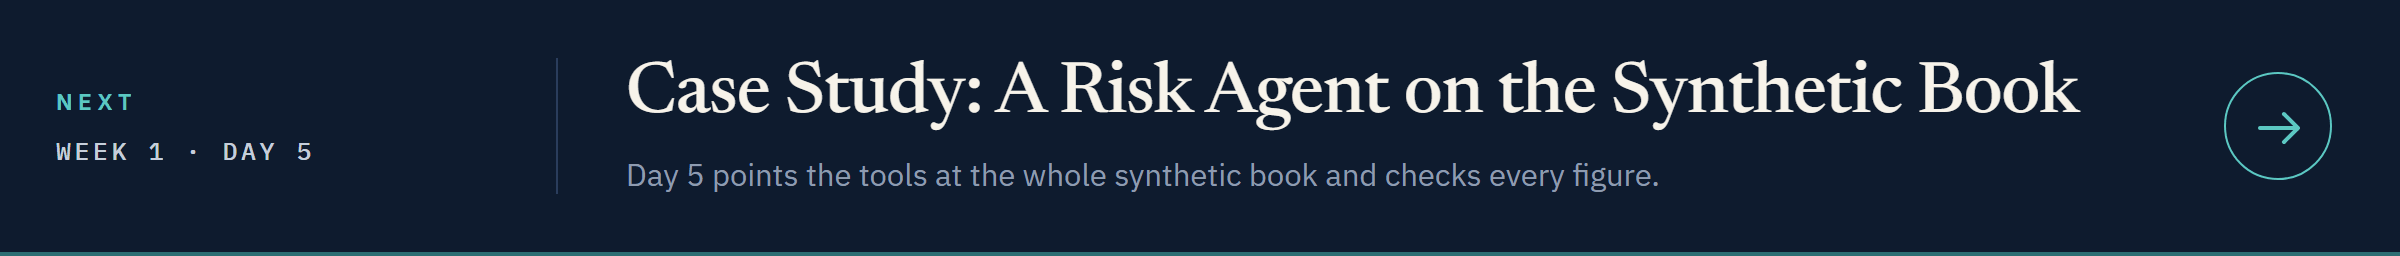](../day5/05_case_study_a_risk_agent_on_the_synthetic_book.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day5/05_case_study_a_risk_agent_on_the_synthetic_book.ipynb)